# ADAS (Advanced Driver Assistance Systems) Telemetria e Segurança em Robotáxis Tesla e Waymo

**Objectivo:** estudo de engenharia de dados sobre telemetria e segurança em robotáxis e sistemas ADAS avançados, a partir de gravações reais de sensores (CAN bus, IMU, LiDAR, GNSS, câmara). Quatro pilares:
1. **Dinâmica do veículo** decodificar telemetria CAN/IMU de um Tesla Model 3 real (velocidade, volante, pedal de travão);
2. **Previsão de manobras críticas** — prever travagens iminentes nos próximos 2 s com base nos 2 s anteriores (função de segurança tipo FCW);
3. **Percepção de objectos** detectar objectos à frente via LiDAR (a classificação de peões/ciclistas com o robotaxi L4 da Waymo fica documentada como extensão natural, ver limitações de P3 e P5);
4. **KPIs de segurança e operação** TTC e near-miss, taxa de eventos por 100 km, conforto (jerk) e latência de inferência.

**Contexto de mercado:**
- **Condução autónoma (SAE Níveis 4 e 5):** classificação oficial de veículos que dispensam completamente o condutor humano — em alguns casos o carro nem sequer tem volante ou pedais.
- **Robotáxis comerciais:** Waymo (antigo projecto da Google/Alphabet, pioneiro dos serviços comerciais com a Waymo One nos EUA) e Tesla Cybercab/Robotaxi (transporte totalmente autónomo por visão computacional, modelos desenhados de raiz sem volante nem pedais).
- **ADAS (Advanced Driver Assistance Systems):** sistemas avançados de assistência ao condutor que utilizam câmaras, radares e sensores LiDAR para analisar o ambiente em tempo real.

**Dados (duas fontes reais, verificadas):**
- **Tesla Model 3** instrumentado ao nível robotaxi gravações ROS2 de 2023-11 a 2024-02 (tfoldi/tesla3_av_rosbags, licença MIT) com CAN bus real (pedal de travão, ângulo e velocidade de rotação do volante, velocidade), LiDAR VLP-16, IMU de 9 eixos, GNSS RTK e 4 câmaras.
- **Waymo motion v1.3.0** robotaxi L4 real (Waymo One) com cenários de 20 s a 10 Hz contendo peões, ciclistas e veículos classificados.

**Nota:** O foco narrativo do estudo é o Tesla Cybercab/Robotaxi: transporte totalmente autónomo por visão computacional, com modelos desenhados de raiz sem volante nem pedais. Por isso privilegiámos a única fonte Tesla disponível — um Model 3 instrumentado com CAN + LiDAR + 4 câmaras (a visão computacional fica documentada como extensão natural do estudo); a classificação de classes de objectos (peões/ciclistas) com o robotaxi real da Waymo é a extensão natural seguinte, registada nas limitações de P3 e P5.

**Estrutura do projecto:**
- Etapa 1 — Métrica de sucesso e KPIs de engenharia (Recall prioritário; TTC, taxa por 100 km, latência, jerk)
- Etapa 2 — Inspeção dos dados brutos (bags ROS do Tesla: CAN, IMU, LiDAR, GNSS; catálogo de campos)
- Etapa 3 — Parsing e extração (decodificação CAN com DBC da Tesla: velocidade, volante, travão; objectos via LiDAR)
- Etapa 4 — Engenharia de features + normalização (StandardScaler)
- Etapa 5 — Divisão temporal treino/teste (sem embaralhar)
- Etapa 6 — Modelação (Random Forest e LSTM para travagem iminente; classificador da classe do objecto como extensão com Waymo)
- Etapa 7 — Visualização e conclusões (viagem temporal, FP/FN, KPIs de segurança)
- P1–P7 — Perguntas de investigação respondidas com os dados
- Conclusão — dados obtidos, modelos e algoritmos, lições de engenharia, limitações e futuro

In [1]:
# ==============================================================================
# STEP 1: MÉTRICA DE SUCESSO DO PROJECTO ADAS
# ==============================================================================
# Objectivo: fixar, antes de tocar nos dados, os critérios do modelo E os
#            KPIs de engenharia usados no mercado AV/ADAS: TTC/near-miss,
#            taxa de eventos por 100 km, latência de inferência e conforto
#            (jerk). Num ADAS, um falso negativo (travagem não prevista) é
#            mais grave do que um falso positivo — o Recall é prioritário.
#
# Input:  nenhum (definição de negócio)
# Output: df_metricas (critérios dos modelos) e df_kpi_eng (KPIs de operação)
#
# Operações:
#   - definir métricas dos modelos (recall, F1, precisão, antecedência)
#   - definir KPIs de engenharia AV/ADAS (TTC, taxa por 100 km, latência, jerk)

import pandas as pd

df_metricas = pd.DataFrame([
    # --- Modelo 1: previsão binária de travagem iminente (Tesla Model 3) ---
    {"modelo": "Previsão de travagem", "métrica": "Recall (classe 'trava')",
     "alvo": ">= 0.80", "justificação": "Falhar uma travagem real é o erro mais grave; o custo de um alerta a mais é baixo."},
    {"modelo": "Previsão de travagem", "métrica": "F1-score",
     "alvo": ">= 0.75", "justificação": "Equilíbrio entre deteção e falsos alertas."},
    {"modelo": "Previsão de travagem", "métrica": "Precisão",
     "alvo": ">= 0.60", "justificação": "Abaixo disto o condutor passa a ignorar os alertas (efeito 'lobo')."},
    {"modelo": "Previsão de travagem", "métrica": "Antecedência média do aviso",
     "alvo": ">= 1.0 s", "justificação": "A 50 km/h, 1 s de aviso dá ~14 m para reagir."},
    # --- Modelo 2: classificador da classe do objecto (Waymo, robotaxi L4) ---
    {"modelo": "Classe do objecto", "métrica": "Precisão — peões",
     "alvo": ">= 0.90", "justificação": "Peão mal classificado pode ser tratado como obstáculo estático."},
    {"modelo": "Classe do objecto", "métrica": "Precisão — ciclistas",
     "alvo": ">= 0.85", "justificação": "Ciclistas têm velocidade própria; confundi-los degrada a travagem."},
    {"modelo": "Classe do objecto", "métrica": "F1 macro (todas as classes)",
     "alvo": ">= 0.70", "justificação": "Garante que o modelo não ignora classes raras."},
])

df_kpi_eng = pd.DataFrame([
    # --- KPIs de engenharia usados em operação por equipas AV/ADAS ---
    {"kpi": "TTC (time-to-collision) mínimo por travagem", "alvo": "medir; near-miss = TTC < 2,0 s",
     "porquê": "TTC é o padrão de segurança (NHTSA) para gravidade de aproximação a objecto."},
    {"kpi": "Taxa de travagens bruscas por 100 km", "alvo": "baseline a medir por viagem",
     "porquê": "KPI de frota: compara condutores/viagens e quantifica risco operacional."},
    {"kpi": "Latência de inferência por janela de 2 s", "alvo": "< 100 ms",
     "porquê": "Acima disso o aviso chega tarde a velocidades de autoestrada — inviável em tempo real."},
    {"kpi": "Jerk (derivada da aceleração) p95 nas travagens", "alvo": "< 5 m/s³",
     "porquê": "Padrão de conforto usado em planeamento de trajectórias AV; jerk alto = desconforto."},
])

display(df_metricas)
display(df_kpi_eng)
print(f"Total: {len(df_metricas)} critérios de modelo + {len(df_kpi_eng)} KPIs de engenharia")

,modelo,métrica,alvo,justificação
0,Previsão de travagem,Recall (classe 'trava'),>= 0.80,Falhar uma travagem real é o erro mais grave; ...
1,Previsão de travagem,F1-score,>= 0.75,Equilíbrio entre deteção e falsos alertas.
2,Previsão de travagem,Precisão,>= 0.60,Abaixo disto o condutor passa a ignorar os ale...
3,Previsão de travagem,Antecedência média do aviso,>= 1.0 s,"A 50 km/h, 1 s de aviso dá ~14 m para reagir."
4,Classe do objecto,Precisão — peões,>= 0.90,Peão mal classificado pode ser tratado como ob...
5,Classe do objecto,Precisão — ciclistas,>= 0.85,Ciclistas têm velocidade própria; confundi-los...
6,Classe do objecto,F1 macro (todas as classes),>= 0.70,Garante que o modelo não ignora classes raras.


,kpi,alvo,porquê
0,TTC (time-to-collision) mínimo por travagem,"medir; near-miss = TTC < 2,0 s",TTC é o padrão de segurança (NHTSA) para gravi...
1,Taxa de travagens bruscas por 100 km,baseline a medir por viagem,KPI de frota: compara condutores/viagens e qua...
2,Latência de inferência por janela de 2 s,< 100 ms,Acima disso o aviso chega tarde a velocidades ...
3,Jerk (derivada da aceleração) p95 nas travagens,< 5 m/s³,Padrão de conforto usado em planeamento de tra...


Total: 7 critérios de modelo + 4 KPIs de engenharia


In [2]:
# ==============================================================================
# STEP 2: INSPECÇÃO DOS DADOS BRUTOS — BAG ROS/MCAP DO TESLA MODEL 3
# ==============================================================================
# Objectivo: descarregar uma gravação real do Tesla (com CAN bus), inventariar
#            todos os tópicos/mensagens, PRIORIZAR os registos robotaxi
#            (foco Tesla Cybercab/Robotaxi: 100% autónomo, sem volante nem
#            pedais, por visão computacional) e catalogar TODOS os campos ROS
#            — mantendo a estrutura completa do dataset (nada é filtrado).
#
# Input:  HuggingFace tfoldi/tesla3_av_rosbags — bag 2024-02-10-14_24_59 (1,1 GB)
# Output: df_topicos (inventário) e df_catalogo (>=77 linhas: campo, tipo,
#         mensagem, descrição)
#
# Operações:
#   - download idempotente do .mcap com verificação de sanidade (tamanho)
#   - abrir com mcap: tópicos, tipos, contagens, duração (secção summary)
#   - priorizar tópicos por relevância robotaxi (alta/média/baixa) — sem filtrar
#   - validar presença dos tópicos críticos (CAN, IMU, LiDAR, GNSS)
#   - extrair msgdef de cada schema -> catálogo de campos
#   - mostrar primeiras 77 linhas do catálogo + total real

%pip install -q mcap

import os, re, urllib.request
import pandas as pd
from mcap.reader import make_reader

PASTA, BAG = "/tmp/tesla_ros", "rosbag2_2024_02_10-14_24_59/rosbag2_2024_02_10-14_24_59_0.mcap"
URL = "https://huggingface.co/datasets/tfoldi/tesla3_av_rosbags/resolve/main/" + BAG
dst = os.path.join(PASTA, os.path.basename(BAG))
os.makedirs(PASTA, exist_ok=True)

if not (os.path.exists(dst) and os.path.getsize(dst) > 1e9):        # idempotente + sanidade
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=1800) as r, open(dst, "wb") as f:
        while (c := r.read(8 << 20)):                               # 8 MB de cada vez
            f.write(c)
print(f"bag em disco: {os.path.getsize(dst)/1e9:.2f} GB")

DESC = {"/vel": "velocidade linear e angular do veículo (odometria/CAN)",
        "/from_can_bus": "frames CAN bus crus do Tesla (ID + payload)",
        "/imu": "acelerómetro + giroscópio + orientação (IMU 9 eixos)",
        "/orientation": "quaternião de orientação estimada",
        "/magnetometer": "campo magnético 3 eixos (bússola)",
        "/navsat/fix": "posição GNSS processada (lat, lon, altitude)",
        "/fix": "posição GNSS processada (segunda antena)",
        "/velodyne_points": "nuvem de pontos LiDAR VLP-16",
        "/scan": "varredura 2D do LiDAR (LaserScan)",
        "/diagnostics": "diagnósticos ROS dos sensores"}

# --- priorização robotaxi (foco Tesla Cybercab/Robotaxi) ---
# O Cybercab é 100% autónomo, sem volante nem pedais, por visão computacional.
# Este Model 3 é o proxy público mais próximo (a Tesla não publica telemetria
# do Cybercab): dinâmica do veículo no CAN + perceção do ambiente por LiDAR.
PRIORIDADE = {
    "/from_can_bus": ("alta", "dinâmica do veículo no CAN (velocidade, volante, travão) — estado interno do robotaxi"),
    "/vel": ("alta", "odometria de velocidade — feedback de movimento"),
    "/imu": ("alta", "IMU 9 eixos — aceleração e jerk em tempo real (conforto)"),
    "/velodyne_points": ("alta", "perceção 3D do ambiente — no Cybercab seria câmara (visão computacional)"),
    "/scan": ("alta", "perceção 2D frontal — distância a objectos, base do FCW"),
    "/fix": ("média", "localização GNSS processada — navegação"),
    "/navsat/fix": ("média", "localização GNSS processada — navegação"),
    "/ubx_nav_hp_pos_llh": ("média", "localização RTK de alta precisão — navegação"),
    "/ubx_nav_status": ("média", "estado do receptor GNSS — integridade da navegação"),
    "/orientation": ("média", "orientação estimada — navegação"),
    "/magnetometer": ("média", "bússola — navegação"),
    "/diagnostics": ("média", "saúde dos sensores — monitorização do sistema"),
    "/velodyne_packets": ("baixa", "pacotes brutos do LiDAR — suporte"),
    "/ntrip_client/rtcm": ("baixa", "correções RTCM do NTRIP — suporte"),
}
# restantes (mensagens u-blox brutas, infraestrutura ROS) ficam em baixa por default

with open(dst, "rb") as f:
    reader = make_reader(f, validate_crcs=False)
    sm = reader.get_summary()                                        # índice do ficheiro
    stats = sm.statistics

    # --- inventário de tópicos ---
    linhas_t = []
    for cid, ch in sm.channels.items():
        sch = sm.schemas[ch.schema_id]
        n = stats.channel_message_counts.get(cid, 0)   # mcap 1.6: contagens por canal
        pr, motivo = PRIORIDADE.get(ch.topic, ("baixa", "mensagens u-blox brutas / infraestrutura ROS"))
        linhas_t.append({"tópico": ch.topic, "tipo ROS": sch.name, "mensagens": n,
                         "prioridade_robotaxi": pr, "motivo_robotaxi": motivo,
                         "descrição": DESC.get(ch.topic, "mensagem u-blox GNSS / infraestrutura ROS")})
    df_topicos = pd.DataFrame(linhas_t)
    df_topicos["_ordem"] = df_topicos["prioridade_robotaxi"].map({"alta": 0, "média": 1, "baixa": 2})
    df_topicos = (df_topicos.sort_values(["_ordem", "mensagens"], ascending=[True, False])
                          .drop(columns="_ordem").reset_index(drop=True))

    # --- catálogo de campos a partir dos msgdef embebidos ---
    # (o separador ROS de definições concatenadas é uma linha de 80 '=')
    linhas_c = []
    for cid, ch in sm.channels.items():
        sch = sm.schemas[ch.schema_id]
        msgdef = sch.data.decode(errors="replace").split("=" * 80)[0]   # 1.ª msg = a principal
        for m in re.finditer(r"^\s*([\w/\[\]]+)\s+(\w+)", msgdef, re.M):  # tipo + nome
            tipo, nome = m.group(1), m.group(2)
            linhas_c.append({"campo": f"{ch.topic}.{nome}", "tipo": tipo,
                             "mensagem": ch.topic,
                             "descrição": f"{DESC.get(ch.topic, sch.name)} — campo '{nome}'"})

    # campos internos do ponto LiDAR (x,y,z,intensity,ring,time) — fora do schema
    for ponto in ["x", "y", "z", "intensity", "ring", "time"]:
        linhas_c.append({"campo": f"/velodyne_points.data.{ponto}", "tipo": "float32/uint16",
                         "mensagem": "/velodyne_points",
                         "descrição": f"coordenada/canal do ponto 3D do LiDAR ({ponto})"})

df_catalogo = pd.DataFrame(linhas_c).drop_duplicates(subset=["campo"]).reset_index(drop=True)

# --- validações de segurança dos dados ---
dur = (stats.message_end_time - stats.message_start_time) / 1e9
print(f"Duração do bag: {dur:.1f} s | Total de mensagens: {stats.message_count:,}")
for t in ["/from_can_bus", "/imu", "/vel", "/velodyne_points", "/navsat/fix"]:
    print(f"  {'OK ' if t in set(df_topicos['tópico']) else 'FALTA'} {t}")
print("Prioridade robotaxi (Cybercab):", df_topicos["prioridade_robotaxi"].value_counts().to_dict())

display(df_topicos)
display(df_catalogo.head(77))
print(f"Total de variáveis catalogadas: {len(df_catalogo)} (mostradas as primeiras 77)")

Note: you may need to restart the kernel to use updated packages.
bag em disco: 1.10 GB
Duração do bag: 148.0 s | Total de mensagens: 315,493
  OK  /from_can_bus
  OK  /imu
  OK  /vel
  OK  /velodyne_points
  OK  /navsat/fix
Prioridade robotaxi (Cybercab): {'baixa': 28, 'média': 7, 'alta': 5}


,tópico,tipo ROS,mensagens,prioridade_robotaxi,motivo_robotaxi,descrição
0,/from_can_bus,ros2_qtcanbus_msgs/msg/QCanBusFrame,301320,alta,"dinâmica do veículo no CAN (velocidade, volant...",frames CAN bus crus do Tesla (ID + payload)
1,/imu,sensor_msgs/msg/Imu,1456,alta,IMU 9 eixos — aceleração e jerk em tempo real ...,acelerómetro + giroscópio + orientação (IMU 9 ...
2,/scan,sensor_msgs/msg/LaserScan,1446,alta,"perceção 2D frontal — distância a objectos, ba...",varredura 2D do LiDAR (LaserScan)
3,/velodyne_points,sensor_msgs/msg/PointCloud2,1443,alta,perceção 3D do ambiente — no Cybercab seria câ...,nuvem de pontos LiDAR VLP-16
4,/vel,geometry_msgs/msg/TwistStamped,0,alta,odometria de velocidade — feedback de movimento,velocidade linear e angular do veículo (odomet...
5,/magnetometer,sensor_msgs/msg/MagneticField,1456,média,bússola — navegação,campo magnético 3 eixos (bússola)
6,/ubx_nav_status,ublox_ubx_msgs/msg/UBXNavStatus,1452,média,estado do receptor GNSS — integridade da naveg...,mensagem u-blox GNSS / infraestrutura ROS
7,/ubx_nav_hp_pos_llh,ublox_ubx_msgs/msg/UBXNavHPPosLLH,1452,média,localização RTK de alta precisão — navegação,mensagem u-blox GNSS / infraestrutura ROS
8,/fix,sensor_msgs/msg/NavSatFix,1452,média,localização GNSS processada — navegação,posição GNSS processada (segunda antena)
9,/diagnostics,diagnostic_msgs/msg/DiagnosticArray,1066,média,saúde dos sensores — monitorização do sistema,diagnósticos ROS dos sensores


,campo,tipo,mensagem,descrição
0,/rosout.DEBUG,byte,/rosout,rcl_interfaces/msg/Log — campo 'DEBUG'
1,/rosout.INFO,byte,/rosout,rcl_interfaces/msg/Log — campo 'INFO'
2,/rosout.WARN,byte,/rosout,rcl_interfaces/msg/Log — campo 'WARN'
3,/rosout.ERROR,byte,/rosout,rcl_interfaces/msg/Log — campo 'ERROR'
4,/rosout.FATAL,byte,/rosout,rcl_interfaces/msg/Log — campo 'FATAL'
...,...,...,...,...
72,/ubx_nav_cov.vel_cov_ne,float32,/ubx_nav_cov,ublox_ubx_msgs/msg/UBXNavCov — campo 'vel_cov_ne'
73,/ubx_nav_cov.vel_cov_nd,float32,/ubx_nav_cov,ublox_ubx_msgs/msg/UBXNavCov — campo 'vel_cov_nd'
74,/ubx_nav_cov.vel_cov_ee,float32,/ubx_nav_cov,ublox_ubx_msgs/msg/UBXNavCov — campo 'vel_cov_ee'
75,/ubx_nav_cov.vel_cov_ed,float32,/ubx_nav_cov,ublox_ubx_msgs/msg/UBXNavCov — campo 'vel_cov_ed'


Total de variáveis catalogadas: 401 (mostradas as primeiras 77)


In [3]:
# ==============================================================================
# STEP 3: PARSING E EXTRAÇÃO — CAN BUS, IMU E LIDAR DO TESLA MODEL 3
# ==============================================================================
# Objectivo: converter o bag bruto em telemetria limpa a 10 Hz — velocidade,
#            volante, acelerador, mudança, travão (iBooster), aceleração IMU e
#            distância ao objecto mais próximo à frente (LiDAR, ±12°).
#
# Input:  bag em cache do STEP 2 + DBC tesla_model3_party (opendbc)
# Output: df_telemetria (10 Hz) — o "car_state" do Tesla
#
# Operações:
#   - descarregar o DBC do Model 3 (se faltar)
#   - percorrer o bag UMA vez: CAN (0x257, 0x129, 0x39D, 0x118) + IMU + scan
#   - reamostrar para grelha fixa de 10 Hz (interpolação temporal)
#   - validar tipos, nulos, gamas; mostrar 20 linhas

%pip install -q mcap cantools

import os, struct, urllib.request
import numpy as np, pandas as pd, cantools
from mcap.reader import make_reader

BAG = "/tmp/tesla_ros/rosbag2_2024_02_10-14_24_59_0.mcap"        # cache do STEP 2
DBC = "/tmp/tesla_dbc/tesla_model3_party.dbc"
os.makedirs("/tmp/tesla_dbc", exist_ok=True)
if not os.path.exists(DBC):                                       # idempotente
    req = urllib.request.Request(
        "https://raw.githubusercontent.com/commaai/opendbc/master/opendbc/dbc/tesla_model3_party.dbc",
        headers={"User-Agent": "Mozilla/5.0"})
    open(DBC, "wb").write(urllib.request.urlopen(req, timeout=60).read())
dbc = cantools.database.load_file(DBC)

def parse_can(b):
    """QCanBusFrame (CDR): header + id + 2 flags + dlc + data."""
    o = 4; o += 8                                                # encaps + sec/nanosec
    ln = struct.unpack_from("<I", b, o)[0]; o += 4 + ln; o = (o + 3) & ~3
    can_id = struct.unpack_from("<I", b, o)[0]; o += 4 + 2
    dlc = b[o]; o += 1
    return can_id, b[o:o + dlc] + b"\x00" * 8                    # padding p/ DBC

def parse_imu(b):
    """sensor_msgs/Imu (CDR): header + quat + covs + gyro + covs + aceleração."""
    o = 4; o += 8
    ln = struct.unpack_from("<I", b, o)[0]; o += 4 + ln
    o = 4 + ((o - 4 + 7) & ~7)                                    # alinhamento double RELATIVO ao CDR (pós-encaps)
    o += (4 + 9 + 3 + 9) * 8                                     # orientação + blocos
    return struct.unpack_from("<3d", b, o)                       # aceleração x,y,z

def parse_scan(b):
    """sensor_msgs/LaserScan (CDR): header + 7 floats + ranges[]."""
    o = 4; o += 8
    ln = struct.unpack_from("<I", b, o)[0]; o += 4 + ln; o = (o + 3) & ~3
    ang_min, _, ang_inc = struct.unpack_from("<3f", b, o)
    o += 7 * 4
    n = struct.unpack_from("<I", b, o)[0]; o += 4
    return ang_min, ang_inc, np.frombuffer(b, "<f4", n, o)

can = {0x257: [], 0x129: [], 0x39D: [], 0x118: []}               # ID -> [(t, sinais)]
imu_t, imu_x, imu_y, imu_z, lid_t, lid_d = [], [], [], [], [], []

with open(BAG, "rb") as f:
    for sch, ch, msg in make_reader(f, validate_crcs=False).iter_messages():
        t = msg.publish_time / 1e9
        if ch.topic == "/from_can_bus":
            cid, data = parse_can(msg.data)
            if cid in can:
                can[cid].append((t, dbc.decode_message(cid, data, decode_choices=False)))
        elif ch.topic == "/imu":
            ax, ay, az = parse_imu(msg.data)
            imu_t.append(t); imu_x.append(ax); imu_y.append(ay); imu_z.append(az)
        elif ch.topic == "/scan":
            ang_min, ang_inc, rng = parse_scan(msg.data)
            ang = ang_min + ang_inc * np.arange(len(rng))
            valid = (rng > 0.5) & (rng < 100.0) & (np.abs(ang) <= np.deg2rad(12))
            lid_t.append(t); lid_d.append(rng[valid].min() if valid.any() else np.nan)

def serie(can_id, campo):
    return (np.array([t for t, _ in can[can_id]]),
            np.array([d[campo] for _, d in can[can_id]]))

t_spd, v  = serie(0x257, "DI_vehicleSpeed")
t_st,  sa = serie(0x129, "SCCM_steeringAngle")
_,     sr = serie(0x129, "SCCM_steeringAngleSpeed")
t_brk, bk = serie(0x39D, "IBST_driverBrakeApply")
t_di,  ap = serie(0x118, "DI_accelPedalPos")
_,     gr = serie(0x118, "DI_gear")

# grelha comum de 10 Hz dentro da janela com cobertura de todos os sinais
t0 = np.ceil(max(t_spd[0], t_st[0], t_brk[0], t_di[0], imu_t[0], lid_t[0]) * 10) / 10
t1 = np.floor(min(t_spd[-1], t_st[-1], t_brk[-1], t_di[-1], imu_t[-1], lid_t[-1]) * 10) / 10
tg = np.arange(t0, t1, 0.1)
interp = lambda ts, vs: np.interp(tg, ts, vs)                    # reamostragem temporal

lid_t2, lid_d2 = np.array(lid_t), np.array(lid_d)
ok = ~np.isnan(lid_d2)                                           # LiDAR: ignora scans vazios
df_telemetria = pd.DataFrame({
    "tempo_s": np.round(tg - t0, 1),
    "velocidade_mps": interp(t_spd, v),
    "angulo_volante_deg": interp(t_st, sa),
    "rotacao_volante_deg_s": interp(t_st, sr),
    "acelerador_pct": interp(t_di, ap),
    "travao_aplicado": interp(t_brk, bk) >= 1.5,                 # 2 = DRIVER_APPLYING_BRAKES
    "mudanca": interp(t_di, gr),
    "dist_objeto_frente_m": interp(lid_t2[ok], lid_d2[ok]),
    "imu_acel_x": interp(np.array(imu_t), np.array(imu_x)),
    "imu_acel_y": interp(np.array(imu_t), np.array(imu_y)),
    "imu_acel_z": interp(np.array(imu_t), np.array(imu_z)),
})

# --- validações de segurança dos dados ---
print(f"Janela: {t0:.1f}–{t1:.1f} s | {len(df_telemetria)} linhas a 10 Hz")
print("Nulos por coluna:", df_telemetria.isna().sum().to_dict())
print(f"Velocidade: [{df_telemetria['velocidade_mps'].min():.1f}, {df_telemetria['velocidade_mps'].max():.1f}] m/s | "
      f"Volante: [{df_telemetria['angulo_volante_deg'].min():.1f}, {df_telemetria['angulo_volante_deg'].max():.1f}]° | "
      f"LiDAR frente: [{df_telemetria['dist_objeto_frente_m'].min():.1f}, {df_telemetria['dist_objeto_frente_m'].max():.1f}] m")
print(f"IMU m/s²: x [{df_telemetria['imu_acel_x'].min():.2f}, {df_telemetria['imu_acel_x'].max():.2f}] | "
      f"y [{df_telemetria['imu_acel_y'].min():.2f}, {df_telemetria['imu_acel_y'].max():.2f}] | "
      f"z [{df_telemetria['imu_acel_z'].min():.2f}, {df_telemetria['imu_acel_z'].max():.2f}]")
eventos = int((df_telemetria["travao_aplicado"].astype(int).diff() == 1).sum())
print(f"Amostras com travão aplicado: {df_telemetria['travao_aplicado'].sum()} | Eventos de travagem: {eventos}")

display(df_telemetria.head(20))

Note: you may need to restart the kernel to use updated packages.
Janela: 1707571501.9–1707571647.3 s | 1454 linhas a 10 Hz
Nulos por coluna: {'tempo_s': 0, 'velocidade_mps': 0, 'angulo_volante_deg': 0, 'rotacao_volante_deg_s': 0, 'acelerador_pct': 0, 'travao_aplicado': 0, 'mudanca': 0, 'dist_objeto_frente_m': 0, 'imu_acel_x': 0, 'imu_acel_y': 0, 'imu_acel_z': 0}
Velocidade: [0.0, 30.6] m/s | Volante: [-361.4, 368.3]° | LiDAR frente: [3.2, 47.4] m
IMU m/s²: x [-2.42, 1.46] | y [-1.49, 2.17] | z [7.43, 12.38]
Amostras com travão aplicado: 80 | Eventos de travagem: 3


,tempo_s,velocidade_mps,angulo_volante_deg,rotacao_volante_deg_s,acelerador_pct,travao_aplicado,mudanca,dist_objeto_frente_m,imu_acel_x,imu_acel_y,imu_acel_z
0,0.0,12.050723,1.200000,-0.489418,20.000000,False,4.0,33.537786,0.767145,0.180157,9.618463
1,0.1,12.148296,1.200000,-0.500000,20.000000,False,4.0,33.245180,0.406437,0.064656,9.859730
2,0.2,12.578993,1.200000,-0.149545,20.000000,False,4.0,32.879598,0.386434,0.242958,10.578061
3,0.3,12.968493,1.400000,2.500000,20.000000,False,4.0,32.534086,0.384288,0.298727,10.654953
4,0.4,13.237004,1.400000,0.167024,20.143968,False,4.0,32.188340,0.302648,0.091317,9.960284
5,0.5,13.381451,1.400000,0.000000,20.016843,False,4.0,31.827511,0.478601,0.189285,9.778104
6,0.6,13.572984,1.700000,3.034986,20.400000,False,4.0,31.417915,0.622071,0.227510,9.575411
7,0.7,13.707275,1.800000,-0.070867,20.072382,False,4.0,31.008318,0.196717,-0.150518,9.302073
8,0.8,13.902483,1.800000,0.000000,20.000000,False,4.0,31.578188,0.440070,0.098428,10.255682
9,0.9,14.133746,1.800000,0.509802,20.000000,False,4.0,33.209322,0.374274,0.184353,10.230514


In [4]:
# ==============================================================================
# STEP 3B: ESTRUTURA DO DATASET — PRIMEIRAS 77 LINHAS, TODAS AS VARIÁVEIS
# ==============================================================================
# Objectivo: inspeccionar a estrutura do df_telemetria (o "car_state" do Tesla)
#            — primeiras 77 linhas com TODAS as colunas visíveis, para perceber
#            o que cada variável representa antes da engenharia de features.
#            É a telemetria que um robotaxi Tesla Cybercab (100% autónomo,
#            sem volante nem pedais) teria de monitorizar por si próprio.
#
# Input:  df_telemetria (STEP 3) — 10 Hz, CAN + IMU + LiDAR do Model 3
# Output: pré-visualização 77 linhas x 11 colunas + dicionário de variáveis
#
# Operações:
#   - mostrar as primeiras 77 linhas com todas as colunas visíveis
#   - dicionário: variável, unidade, origem (sensor/mensagem CAN), papel no pipeline

import pandas as pd

pd.set_option("display.max_columns", None)              # TODAS as colunas visíveis
display(df_telemetria.head(77))

# --- dicionário de variáveis: o que é cada coluna e de onde vem ---
df_dicionario = pd.DataFrame([
    {"variável": "tempo_s", "unidade": "s", "origem": "grelha 10 Hz",
     "papel": "tempo decorrido desde o início da janela de análise"},
    {"variável": "velocidade_mps", "unidade": "m/s", "origem": "CAN 0x257 (DI_vehicleSpeed)",
     "papel": "velocidade real do veículo — base do cálculo de TTC e distância"},
    {"variável": "angulo_volante_deg", "unidade": "°", "origem": "CAN 0x129 (SCCM_steeringAngle)",
     "papel": "posição do volante — preditor de manobra (curva antes de travar)"},
    {"variável": "rotacao_volante_deg_s", "unidade": "°/s", "origem": "CAN 0x129 (SCCM_steeringAngleSpeed)",
     "papel": "velocidade de rotação do volante — manobra brusca"},
    {"variável": "acelerador_pct", "unidade": "%", "origem": "CAN 0x118 (DI_accelPedalPos)",
     "papel": "posição do pedal do acelerador — soltar o pedal antecede travagem"},
    {"variável": "travao_aplicado", "unidade": "bool", "origem": "CAN 0x39D (IBST_driverBrakeApply=2)",
     "papel": "condutor a travar — ALVO do modelo de previsão (FCW)"},
    {"variável": "mudanca", "unidade": "—", "origem": "CAN 0x118 (DI_gear)",
     "papel": "mudança engatada (P/R/N/D) — contexto da viagem"},
    {"variável": "dist_objeto_frente_m", "unidade": "m", "origem": "LiDAR /scan (sector ±12°)",
     "papel": "objecto mais próximo à frente — aproximação = risco de travagem"},
    {"variável": "imu_acel_x", "unidade": "m/s²", "origem": "IMU 9 eixos (eixo x)",
     "papel": "aceleração longitudinal — travagens bruscas e jerk (conforto)"},
    {"variável": "imu_acel_y", "unidade": "m/s²", "origem": "IMU 9 eixos (eixo y)",
     "papel": "aceleração lateral — curvas e manobras de evasão"},
    {"variável": "imu_acel_z", "unidade": "m/s²", "origem": "IMU 9 eixos (eixo z)",
     "papel": "aceleração vertical — irregularidades da via (sanidade do IMU)"},
])
display(df_dicionario)

print(f"Dimensões: {df_telemetria.shape[0]} linhas x {df_telemetria.shape[1]} colunas | Frequência: 10 Hz | "
      f"Duração coberta: {df_telemetria.shape[0]/10:.1f} s")

,tempo_s,velocidade_mps,angulo_volante_deg,rotacao_volante_deg_s,acelerador_pct,travao_aplicado,mudanca,dist_objeto_frente_m,imu_acel_x,imu_acel_y,imu_acel_z
0,0.0,12.050723,1.200000,-0.489418,20.000000,False,4.0,33.537786,0.767145,0.180157,9.618463
1,0.1,12.148296,1.200000,-0.500000,20.000000,False,4.0,33.245180,0.406437,0.064656,9.859730
2,0.2,12.578993,1.200000,-0.149545,20.000000,False,4.0,32.879598,0.386434,0.242958,10.578061
3,0.3,12.968493,1.400000,2.500000,20.000000,False,4.0,32.534086,0.384288,0.298727,10.654953
4,0.4,13.237004,1.400000,0.167024,20.143968,False,4.0,32.188340,0.302648,0.091317,9.960284
...,...,...,...,...,...,...,...,...,...,...,...
72,7.2,25.806918,5.697425,-8.716125,24.000000,False,4.0,30.031950,0.549770,0.430344,10.254220
73,7.3,26.049748,4.530936,-12.190636,24.000000,False,4.0,29.236301,0.671905,0.384793,11.407876
74,7.4,26.320000,2.756347,-19.000000,22.800000,False,4.0,28.561064,0.853752,0.130741,9.567137
75,7.5,26.500744,1.722135,-10.217403,22.800000,False,4.0,27.906424,0.568244,0.236895,10.987828


,variável,unidade,origem,papel
0,tempo_s,s,grelha 10 Hz,tempo decorrido desde o início da janela de an...
1,velocidade_mps,m/s,CAN 0x257 (DI_vehicleSpeed),velocidade real do veículo — base do cálculo d...
2,angulo_volante_deg,°,CAN 0x129 (SCCM_steeringAngle),posição do volante — preditor de manobra (curv...
3,rotacao_volante_deg_s,°/s,CAN 0x129 (SCCM_steeringAngleSpeed),velocidade de rotação do volante — manobra brusca
4,acelerador_pct,%,CAN 0x118 (DI_accelPedalPos),posição do pedal do acelerador — soltar o peda...
5,travao_aplicado,bool,CAN 0x39D (IBST_driverBrakeApply=2),condutor a travar — ALVO do modelo de previsão...
6,mudanca,—,CAN 0x118 (DI_gear),mudança engatada (P/R/N/D) — contexto da viagem
7,dist_objeto_frente_m,m,LiDAR /scan (sector ±12°),objecto mais próximo à frente — aproximação = ...
8,imu_acel_x,m/s²,IMU 9 eixos (eixo x),aceleração longitudinal — travagens bruscas e ...
9,imu_acel_y,m/s²,IMU 9 eixos (eixo y),aceleração lateral — curvas e manobras de evasão


Dimensões: 1454 linhas x 11 colunas | Frequência: 10 Hz | Duração coberta: 145.4 s


In [5]:
# ==============================================================================
# STEP 4: ENGENHARIA DE FEATURES — DO "CAR_STATE" ÀS ENTRADAS DO MODELO FCW
# ==============================================================================
# Objectivo: derivar de df_telemetria as features que antecedem uma travagem
#            (aceleração e jerk via CAN, aproximação ao objecto à frente,
#            distância percorrida por janela de 2 s, manobra brusca) e
#            normalizá-las com StandardScaler — o mesmo pré-processamento que
#            o robotaxi Tesla Cybercab aplicaria antes da inferência do FCW.
#
# Input:  df_telemetria (STEP 3) — 10 Hz, CAN + IMU + LiDAR do Model 3
# Output: df_features (features cruas + indicadores) e df_features_z (normalizadas)
#
# Operações:
#   - aceleração longitudinal = derivada numérica da velocidade CAN (10 Hz)
#   - jerk = derivada da aceleração (conforto; KPI p95 < 5 m/s³)
#   - indicador de manobra brusca = aceleração < -3 m/s²
#   - distância percorrida na janela de 2 s anteriores (integral da velocidade)
#   - aproximação ao objecto à frente + TTC instantâneo (near-miss NHTSA < 2 s)
#   - queda do acelerador em 1 s (soltar o pedal antecede travagem)
#   - StandardScaler ajustado SÓ aos primeiros 70% (treino temporal) — sem leakage

import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler

df_features = df_telemetria.copy()
dt = 0.1                                                       # 10 Hz

# --- features dinâmicas derivadas do CAN ---
df_features["aceleracao_mps2"] = df_features["velocidade_mps"].diff() / dt
df_features["jerk_mps3"] = df_features["aceleracao_mps2"].diff() / dt
df_features["manobra_brusca"] = df_features["aceleracao_mps2"] < -3.0      # indicador pedido
df_features["queda_acelerador_1s"] = df_features["acelerador_pct"] - df_features["acelerador_pct"].shift(10)

# --- distância percorrida na janela de 2 s anteriores (20 amostras) ---
df_features["distancia_janela_2s_m"] = (df_features["velocidade_mps"] * dt).rolling(20).sum()

# --- aproximação ao objecto à frente e TTC instantâneo ---
df_features["aproximacao_frente_mps"] = -df_features["dist_objeto_frente_m"].diff() / dt   # >0 = a aproximar
df_features["ttc_frente_s"] = np.where(df_features["aproximacao_frente_mps"] > 0.5,
                                      df_features["dist_objeto_frente_m"] / df_features["aproximacao_frente_mps"],
                                      np.nan)                  # TTC só é definido a aproximar-se

# --- normalização StandardScaler (ajuste só ao treino temporal, 70%) ---
# Porquê StandardScaler: as features vivem em escalas muito diferentes
# (graus do volante vs m/s² vs metros); sem normalizar, umas dominam as outras
# nos modelos de distância/gradiente e o treino fica enviesado. Com média 0 e
# desvio 1 todas pesam igual. Ajustar SÓ ao treino evita que a média/desvio
# do futuro (teste) vazem para o pré-processamento (data leakage).
FEATURES = ["velocidade_mps", "angulo_volante_deg", "rotacao_volante_deg_s",
            "acelerador_pct", "dist_objeto_frente_m", "imu_acel_x", "imu_acel_y",
            "aceleracao_mps2", "jerk_mps3", "queda_acelerador_1s",
            "distancia_janela_2s_m", "aproximacao_frente_mps"]
n_treino = int(len(df_features) * 0.7)                         # corte temporal (STEP 5 reutiliza)
scaler = StandardScaler().fit(df_features[FEATURES].iloc[:n_treino])
df_features_z = pd.DataFrame(scaler.transform(df_features[FEATURES]),
                             columns=[f + "_z" for f in FEATURES])

# --- validações de segurança das features ---
print(f"Features: {len(df_features)} linhas | {len(FEATURES)} normalizadas + indicadores")
print(f"Manobras bruscas (aceleração < -3 m/s²): {int(df_features['manobra_brusca'].sum())} amostras")
print(f"Queda do acelerador > 20 pp em 1 s: {(df_features['queda_acelerador_1s'] < -20).sum()} amostras")
print(f"Aceleração: [{df_features['aceleracao_mps2'].min():.2f}, {df_features['aceleracao_mps2'].max():.2f}] m/s² | "
      f"Jerk p95: {df_features['jerk_mps3'].abs().quantile(0.95):.2f} m/s³")
print(f"TTC instantâneo definido em {df_features['ttc_frente_s'].notna().sum()} amostras | "
      f"near-miss (TTC < 2 s): {(df_features['ttc_frente_s'] < 2).sum()}")
print(f"Treino do scaler: primeiras {n_treino} amostras | médias ≈ {np.round(scaler.mean_[:3], 3)}")

display(df_features[["tempo_s"] + FEATURES + ["travao_aplicado", "manobra_brusca", "ttc_frente_s"]].head(20))
display(df_features_z.head(20))

Features: 1454 linhas | 12 normalizadas + indicadores
Manobras bruscas (aceleração < -3 m/s²): 116 amostras
Queda do acelerador > 20 pp em 1 s: 0 amostras
Aceleração: [-8.14, 4.31] m/s² | Jerk p95: 13.46 m/s³
TTC instantâneo definido em 849 amostras | near-miss (TTC < 2 s): 128
Treino do scaler: primeiras 1017 amostras | médias ≈ [ 19.585 -40.894  -0.505]


,tempo_s,velocidade_mps,angulo_volante_deg,rotacao_volante_deg_s,acelerador_pct,dist_objeto_frente_m,imu_acel_x,imu_acel_y,aceleracao_mps2,jerk_mps3,queda_acelerador_1s,distancia_janela_2s_m,aproximacao_frente_mps,travao_aplicado,manobra_brusca,ttc_frente_s
0,0.0,12.050723,1.200000,-0.489418,20.000000,33.537786,0.767145,0.180157,NaN,NaN,NaN,NaN,NaN,False,False,NaN
1,0.1,12.148296,1.200000,-0.500000,20.000000,33.245180,0.406437,0.064656,0.975728,NaN,NaN,NaN,2.926056,False,False,11.361773
2,0.2,12.578993,1.200000,-0.149545,20.000000,32.879598,0.386434,0.242958,4.306980,33.312517,NaN,NaN,3.655819,False,False,8.993770
3,0.3,12.968493,1.400000,2.500000,20.000000,32.534086,0.384288,0.298727,3.894997,-4.119832,NaN,NaN,3.455121,False,False,9.416194
4,0.4,13.237004,1.400000,0.167024,20.143968,32.188340,0.302648,0.091317,2.685107,-12.098890,NaN,NaN,3.457459,False,False,9.309825
5,0.5,13.381451,1.400000,0.000000,20.016843,31.827511,0.478601,0.189285,1.444469,-12.406386,NaN,NaN,3.608288,False,False,8.820669
6,0.6,13.572984,1.700000,3.034986,20.400000,31.417915,0.622071,0.227510,1.915331,4.708625,NaN,NaN,4.095966,False,False,7.670453
7,0.7,13.707275,1.800000,-0.070867,20.072382,31.008318,0.196717,-0.150518,1.342909,-5.724223,NaN,NaN,4.095966,False,False,7.570453
8,0.8,13.902483,1.800000,0.000000,20.000000,31.578188,0.440070,0.098428,1.952084,6.091747,NaN,NaN,-5.698695,False,False,NaN
9,0.9,14.133746,1.800000,0.509802,20.000000,33.209322,0.374274,0.184353,2.312629,3.605453,NaN,NaN,-16.311341,False,False,NaN


,velocidade_mps_z,angulo_volante_deg_z,rotacao_volante_deg_s_z,acelerador_pct_z,dist_objeto_frente_m_z,imu_acel_x_z,imu_acel_y_z,aceleracao_mps2_z,jerk_mps3_z,queda_acelerador_1s_z,distancia_janela_2s_m_z,aproximacao_frente_mps_z
0,-0.869890,0.521079,0.000363,0.671609,1.524982,1.261770,-0.530335,NaN,NaN,NaN,NaN,NaN
1,-0.858624,0.521079,0.000116,0.671609,1.492522,0.618130,-0.776349,0.554768,NaN,NaN,NaN,0.112462
2,-0.808894,0.521079,0.008307,0.671609,1.451967,0.582436,-0.396571,2.320027,4.775411,NaN,NaN,0.142992
3,-0.763921,0.523555,0.070231,0.671609,1.413638,0.578608,-0.277784,2.101714,-0.582845,NaN,NaN,0.134596
4,-0.732918,0.523555,0.015705,0.694184,1.375284,0.432930,-0.719563,1.460583,-1.725008,NaN,NaN,0.134694
5,-0.716239,0.523555,0.011802,0.674250,1.335256,0.746898,-0.510893,0.803158,-1.769024,NaN,NaN,0.141004
6,-0.694124,0.527269,0.082735,0.734331,1.289818,1.002903,-0.429474,1.052672,0.680905,NaN,NaN,0.161406
7,-0.678619,0.528506,0.010145,0.682959,1.244380,0.243909,-1.234665,0.749341,-0.812506,NaN,NaN,0.161406
8,-0.656079,0.528506,0.011802,0.671609,1.307597,0.678144,-0.704416,1.072148,0.878892,NaN,NaN,-0.248358
9,-0.629377,0.528506,0.023717,0.671609,1.488545,0.560739,-0.521397,1.263204,0.522992,NaN,NaN,-0.692343


In [6]:
# ==============================================================================
# STEP 5: DIVISÃO TREINO/TESTE TEMPORAL — SEM EMBARALHAR (Etapa 5)
# ==============================================================================
# Objectivo: separar os dados CRONOLOGICAMENTE (passado -> treino; futuro ->
#            teste), sem shuffle, para que o modelo nunca treine com informação
#            do futuro — tal como um robotaxi real, que só tem o passado para
#            decidir. Embaralhar criaria data leakage: o modelo “veria” o futuro.
#
# Input:  df_features (STEP 4) + n_treino (corte 70% já usado no StandardScaler)
# Output: treino e teste (dataframes temporais) + verificação de desequilíbrio
#
# Operações:
#   - corte temporal único 70/30 (o MESMO do scaler — consistência)
#   - sem embaralhamento (fatia temporal, não amostragem aleatória)
#   - comparar a taxa de travagens nos dois lados (representatividade)

import pandas as pd

treino = df_features.iloc[:n_treino].copy()                  # primeiros 70% do tempo
teste  = df_features.iloc[n_treino:].copy()                   # últimos 30% do tempo

# --- validações: disjunção temporal e representatividade das classes ---
assert treino["tempo_s"].max() < teste["tempo_s"].min(), "Sobreposição temporal!"
print(f"Treino: {len(treino)} amostras ({treino['tempo_s'].min():.1f}–{treino['tempo_s'].max():.1f} s) | "
      f"Teste: {len(teste)} amostras ({teste['tempo_s'].min():.1f}–{teste['tempo_s'].max():.1f} s)")
print(f"Corte temporal disjunto: treino acaba em {treino['tempo_s'].max():.1f} s, "
      f"teste começa em {teste['tempo_s'].min():.1f} s")
print(f"Travões no treino: {int(treino['travao_aplicado'].sum())} ({treino['travao_aplicado'].mean()*100:.1f}%) | "
      f"no teste: {int(teste['travao_aplicado'].sum())} ({teste['travao_aplicado'].mean()*100:.1f}%)")

df_resumo_split = pd.DataFrame([
    {"conjunto": "treino", "amostras": len(treino), "janela_s": f"{treino['tempo_s'].min():.1f}–{treino['tempo_s'].max():.1f}",
     "travao": int(treino['travao_aplicado'].sum()), "pct_travao": round(treino['travao_aplicado'].mean()*100, 1)},
    {"conjunto": "teste", "amostras": len(teste), "janela_s": f"{teste['tempo_s'].min():.1f}–{teste['tempo_s'].max():.1f}",
     "travao": int(teste['travao_aplicado'].sum()), "pct_travao": round(teste['travao_aplicado'].mean()*100, 1)},
])
display(df_resumo_split)

Treino: 1017 amostras (0.0–101.6 s) | Teste: 437 amostras (101.7–145.3 s)
Corte temporal disjunto: treino acaba em 101.6 s, teste começa em 101.7 s
Travões no treino: 2 (0.2%) | no teste: 78 (17.8%)


,conjunto,amostras,janela_s,travao,pct_travao
0,treino,1017,0.0–101.6,2,0.2
1,teste,437,101.7–145.3,78,17.8


In [7]:
# ==============================================================================
# STEP 6: MODELAÇÃO — PREVER TRAVAGEM IMINENTE NOS PRÓXIMOS 2 S (FCW)
# ==============================================================================
# Objectivo: treinar o classificador binário do pedido original — prever se o
#            veículo vai travar nos próximos 2 s com base nos 2 s anteriores
#            (janelas de 20+20 amostras a 10 Hz). Limitação assumida (opção C):
#            este bag tem só 3 eventos de travagem, quase todos no fim da
#            viagem — o resultado documenta o que acontece num FCW quando o
#            treino tem poucos eventos raros, o cenário real de um robotaxi
#            sem frota de dados de corner cases.
#
# Input:  df_features + df_features_z + n_treino (STEP 4/5)
# Output: métricas (precisão, recall, F1), matriz de confusão, baseline,
#         antecedência do aviso e importância das features
#
# Operações:
#   - construir janelas 2 s história -> 2 s futuro (sem atravessar o corte)
#   - Random Forest baseline com class_weight="balanced" (desequilíbrio)
#   - avaliar contra os alvos do STEP 1 + baseline "nunca trava"
#   - antecedência do aviso nos verdadeiros-positivos (alvo >= 1,0 s)

import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

H, F = 20, 20                                        # 2 s de história, 2 s de futuro (10 Hz)

# frame de modelação: tempo + alvo + as 12 features normalizadas
df_modelo = pd.concat([df_features[["tempo_s", "travao_aplicado"]].reset_index(drop=True),
                       df_features_z.reset_index(drop=True)], axis=1)
COLS_Z = [c for c in df_modelo.columns if c.endswith("_z")]

def janelas(df):
    """Cada janela = 20 passos x 12 features achatados; rótulo = travar nos 2 s seguintes."""
    vals = df[COLS_Z].to_numpy()
    alvo, t = df["travao_aplicado"].to_numpy(), df["tempo_s"].to_numpy()
    X, y, ts = [], [], []
    for i in range(len(df) - H - F + 1):
        w = vals[i:i+H]
        if np.isnan(w).any(): continue              # só janelas completas, sem NaN
        X.append(w.ravel()); y.append(alvo[i+H:i+H+F].any()); ts.append(t[i])
    return np.array(X), np.array(y), np.array(ts)

# janelas construídas DENTRO de cada lado — nenhuma atravessa o corte temporal
X_tr, y_tr, _ = janelas(df_modelo.iloc[:n_treino])
X_te, y_te, t_te = janelas(df_modelo.iloc[n_treino:])
print(f"Janelas — treino: {len(y_tr)} ({int(y_tr.sum())} positivas) | "
      f"teste: {len(y_te)} ({int(y_te.sum())} positivas)")

# --- Random Forest baseline: 300 árvores, pesos balanceados para a classe rara ---
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1).fit(X_tr, y_tr)
pred = rf.predict(X_te)
proba = rf.predict_proba(X_te)[:, 1]

prec = precision_score(y_te, pred, zero_division=0)
rec  = recall_score(y_te, pred, zero_division=0)
f1   = f1_score(y_te, pred, zero_division=0)
acc  = (pred == y_te).mean()
acc_base = (y_te == 0).mean()                         # baseline "nunca trava"
cm = confusion_matrix(y_te, pred)

print(f"Precisão: {prec:.2f} (alvo >= 0.60) | Recall: {rec:.2f} (alvo >= 0.80) | F1: {f1:.2f} (alvo >= 0.75)")
print(f"Accuracy do modelo: {acc:.2f} | Accuracy do baseline 'nunca trava': {acc_base:.2f} — "
      f"accuracy engana com classes desequilibradas")

df_aval = pd.DataFrame([
    {"métrica": "Recall (classe 'trava')", "obtido": round(rec, 2), "alvo": ">= 0.80", "cumpre": rec >= 0.80},
    {"métrica": "F1-score", "obtido": round(f1, 2), "alvo": ">= 0.75", "cumpre": f1 >= 0.75},
    {"métrica": "Precisão", "obtido": round(prec, 2), "alvo": ">= 0.60", "cumpre": prec >= 0.60},
    {"métrica": "Accuracy", "obtido": round(acc, 2), "alvo": "—", "cumpre": "—"},
])
display(df_aval)
display(pd.DataFrame(cm, index=["real: não trava", "real: trava"],
                     columns=["prev: não trava", "prev: trava"]))

# --- antecedência do aviso: quanto tempo antes do início da travagem o modelo alerta ---
onsets = teste["tempo_s"][teste["travao_aplicado"].astype(int).diff() == 1].to_numpy()
antecedencias = []
for o in onsets:
    tps = t_te[(pred == 1) & (y_te == 1) & (t_te <= o) & (t_te >= o - 4)]
    if len(tps):
        antecedencias.append(o - tps.min())
if antecedencias:
    print(f"Eventos de travagem no teste: {len(onsets)} | antecedência média do aviso: "
          f"{np.mean(antecedencias):.1f} s (alvo >= 1,0 s)")
else:
    print(f"Eventos de travagem no teste: {len(onsets)} | antecedência: sem verdadeiros-positivos "
          "para medir — limitação do bag único")

# --- importância das features: o que antecede a travagem? ---
imp = rf.feature_importances_
print("Top 5 features (passo da janela em que entram):")
for k in np.argsort(imp)[::-1][:5]:
    passo, feat = divmod(k, len(FEATURES))
    print(f"  {FEATURES[feat]:24s} t-{(H-passo)*0.1:3.1f} s   peso {imp[k]:.3f}")

print("\nDiscussão do desequilíbrio: o treino tem pouquíssimas janelas positivas "
      "(eventos raros no fim da viagem). Usámos class_weight='balanced' para "
      "penalizar mais os falsos negativos; gerar eventos sintéticos (SMOTE) "
      "em dados de segurança seria arriscado — eventos inventados podem "
      "ensinar padrões de travagem irreais. A solução real é mais frota: mais "
      "bags, mais viagens, como a Waymo faz com a sua frota L4.")

Janelas — treino: 959 (21 positivas) | teste: 398 (116 positivas)
Precisão: 0.00 (alvo >= 0.60) | Recall: 0.00 (alvo >= 0.80) | F1: 0.00 (alvo >= 0.75)
Accuracy do modelo: 0.71 | Accuracy do baseline 'nunca trava': 0.71 — accuracy engana com classes desequilibradas


,métrica,obtido,alvo,cumpre
0,Recall (classe 'trava'),0.00,>= 0.80,False
1,F1-score,0.00,>= 0.75,False
2,Precisão,0.00,>= 0.60,False
3,Accuracy,0.71,—,—


,prev: não trava,prev: trava
real: não trava,282,0
real: trava,116,0


Eventos de travagem no teste: 2 | antecedência: sem verdadeiros-positivos para medir — limitação do bag único
Top 5 features (passo da janela em que entram):
  distancia_janela_2s_m    t-1.9 s   peso 0.065
  distancia_janela_2s_m    t-2.0 s   peso 0.060
  distancia_janela_2s_m    t-1.4 s   peso 0.037
  distancia_janela_2s_m    t-1.5 s   peso 0.037
  distancia_janela_2s_m    t-1.3 s   peso 0.036

Discussão do desequilíbrio: o treino tem pouquíssimas janelas positivas (eventos raros no fim da viagem). Usámos class_weight='balanced' para penalizar mais os falsos negativos; gerar eventos sintéticos (SMOTE) em dados de segurança seria arriscado — eventos inventados podem ensinar padrões de travagem irreais. A solução real é mais frota: mais bags, mais viagens, como a Waymo faz com a sua frota L4.


In [8]:
# ==============================================================================
# STEP 3B: DATASET LIMPO — ESQUEMA (dtypes) E PRIMEIRAS 77 LINHAS NUMA TABELA ÚNICA
# ==============================================================================
# Objectivo: completar a inspecção com a visão do dataset JÁ LIMPO — o
#            df_telemetria (o "car_state" a 10 Hz que um Tesla Cybercab/
#            Robotaxi monitorizaria por si próprio, sem condutor): esquema com
#            os tipos de dados de cada coluna e as primeiras 77 linhas com
#            TODAS as colunas numa única tabela.
#
# Input:  df_telemetria (STEP 3) — CAN + IMU + LiDAR do Model 3 a 10 Hz
# Output: df_esquema (coluna, dtype, unidade, origem, papel) + tabela única 77x11
#
# Operações:
#   - dtypes do dataset limpo (equivalente pandas ao printSchema do Spark)
#   - tabela única: primeiras 77 linhas, todas as colunas visíveis
#   - resumo de dimensões, frequência e duração da viagem

import pandas as pd

META = {
    "tempo_s":            ("s",    "grelha 10 Hz",                  "tempo decorrido desde o início da janela"),
    "velocidade_mps":     ("m/s",  "CAN 0x257 (DI_vehicleSpeed)",   "velocidade real do veículo"),
    "angulo_volante_deg": ("°",    "CAN 0x129 (SCCM_steeringAngle)", "posição do volante"),
    "rotacao_volante_deg_s": ("°/s", "CAN 0x129 (SCCM_steeringAngleSpeed)", "velocidade de rotação do volante"),
    "acelerador_pct":     ("%",    "CAN 0x118 (DI_accelPedalPos)",  "posição do pedal do acelerador"),
    "travao_aplicado":    ("bool", "CAN 0x39D (IBST_driverBrakeApply=2)", "condutor a travar — ALVO do FCW"),
    "mudanca":            ("—",    "CAN 0x118 (DI_gear)",          "mudança engatada"),
    "dist_objeto_frente_m": ("m",  "LiDAR /scan (sector ±12°)",    "objecto mais próximo à frente"),
    "imu_acel_x":         ("m/s²", "IMU 9 eixos (eixo x)",         "aceleração longitudinal"),
    "imu_acel_y":         ("m/s²", "IMU 9 eixos (eixo y)",         "aceleração lateral"),
    "imu_acel_z":         ("m/s²", "IMU 9 eixos (eixo z)",         "aceleração vertical"),
}

# --- esquema (printSchema em pandas): coluna, dtype, unidade, origem, papel ---
df_esquema = pd.DataFrame([
    {"coluna": c, "dtype": str(df_telemetria[c].dtype), "unidade": META[c][0],
     "origem": META[c][1], "papel": META[c][2]}
    for c in df_telemetria.columns
])
display(df_esquema)

# --- tabela única: primeiras 77 linhas com TODAS as colunas ---
pd.set_option("display.max_columns", None)
display(df_telemetria.head(77))

print(f"Esquema: {df_telemetria.shape[1]} colunas | Dataset: {df_telemetria.shape[0]} linhas a 10 Hz "
      f"({df_telemetria.shape[0]/10:.1f} s de viagem)")

,coluna,dtype,unidade,origem,papel
0,tempo_s,float64,s,grelha 10 Hz,tempo decorrido desde o início da janela
1,velocidade_mps,float64,m/s,CAN 0x257 (DI_vehicleSpeed),velocidade real do veículo
2,angulo_volante_deg,float64,°,CAN 0x129 (SCCM_steeringAngle),posição do volante
3,rotacao_volante_deg_s,float64,°/s,CAN 0x129 (SCCM_steeringAngleSpeed),velocidade de rotação do volante
4,acelerador_pct,float64,%,CAN 0x118 (DI_accelPedalPos),posição do pedal do acelerador
5,travao_aplicado,bool,bool,CAN 0x39D (IBST_driverBrakeApply=2),condutor a travar — ALVO do FCW
6,mudanca,float64,—,CAN 0x118 (DI_gear),mudança engatada
7,dist_objeto_frente_m,float64,m,LiDAR /scan (sector ±12°),objecto mais próximo à frente
8,imu_acel_x,float64,m/s²,IMU 9 eixos (eixo x),aceleração longitudinal
9,imu_acel_y,float64,m/s²,IMU 9 eixos (eixo y),aceleração lateral


,tempo_s,velocidade_mps,angulo_volante_deg,rotacao_volante_deg_s,acelerador_pct,travao_aplicado,mudanca,dist_objeto_frente_m,imu_acel_x,imu_acel_y,imu_acel_z
0,0.0,12.050723,1.200000,-0.489418,20.000000,False,4.0,33.537786,0.767145,0.180157,9.618463
1,0.1,12.148296,1.200000,-0.500000,20.000000,False,4.0,33.245180,0.406437,0.064656,9.859730
2,0.2,12.578993,1.200000,-0.149545,20.000000,False,4.0,32.879598,0.386434,0.242958,10.578061
3,0.3,12.968493,1.400000,2.500000,20.000000,False,4.0,32.534086,0.384288,0.298727,10.654953
4,0.4,13.237004,1.400000,0.167024,20.143968,False,4.0,32.188340,0.302648,0.091317,9.960284
...,...,...,...,...,...,...,...,...,...,...,...
72,7.2,25.806918,5.697425,-8.716125,24.000000,False,4.0,30.031950,0.549770,0.430344,10.254220
73,7.3,26.049748,4.530936,-12.190636,24.000000,False,4.0,29.236301,0.671905,0.384793,11.407876
74,7.4,26.320000,2.756347,-19.000000,22.800000,False,4.0,28.561064,0.853752,0.130741,9.567137
75,7.5,26.500744,1.722135,-10.217403,22.800000,False,4.0,27.906424,0.568244,0.236895,10.987828


Esquema: 11 colunas | Dataset: 1454 linhas a 10 Hz (145.4 s de viagem)


In [9]:
# ==============================================================================
# STEP 6B: LSTM — REDE RECORRENTE PARA A SEQUÊNCIA TEMPORAL (extra da Etapa 6)
# ==============================================================================
# Objectivo: o plano pedia "se houver GPU, experimenta uma rede recorrente
#            simples com LSTM para captar a sequência temporal". O compute
#            serverless não tem GPU: treinamos uma LSTM reduzida em CPU e
#            documentamos a limitação honestamente.
#
# Input:  janelas do STEP 6 (X_tr, y_tr, X_te, y_te) — 2 s de história (20, 12)
# Output: métricas LSTM vs Random Forest + comparação com os alvos
#
# Operações:
#   - verificar GPU (torch.cuda.is_available)
#   - LSTM (12 features -> 32 hidden -> 1 logit) com BCEWithLogitsLoss
#     e pos_weight (desequilíbrio: penaliza os falsos negativos)
#   - treinar 40 épocas e avaliar precisão/recall/F1 no teste

try:
    import torch
except ModuleNotFoundError:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
    import torch

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {DEV} — {'GPU disponível' if DEV == 'cuda' else 'sem GPU no serverless: LSTM reduzida em CPU (documentado)'}")

# janelas achatadas (n, 240) -> sequências (n, 20 passos, 12 features)
Xtr = torch.tensor(X_tr.reshape(-1, H, len(FEATURES)), dtype=torch.float32, device=DEV)
ytr = torch.tensor(y_tr.astype(np.float32), dtype=torch.float32, device=DEV)
Xte = torch.tensor(X_te.reshape(-1, H, len(FEATURES)), dtype=torch.float32, device=DEV)

class FCW_LSTM(torch.nn.Module):
    """LSTM simples: lê a sequência de 2 s e classifica 'trava nos próximos 2 s'."""
    def __init__(self, n_in, n_hidden=32):
        super().__init__()
        self.lstm = torch.nn.LSTM(n_in, n_hidden, batch_first=True)
        self.fc = torch.nn.Linear(n_hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)                       # (n, 20 passos, hidden)
        return self.fc(out[:, -1, :]).squeeze(-1)   # último passo -> logit

torch.manual_seed(42)
modelo_lstm = FCW_LSTM(len(FEATURES)).to(DEV)
pos_weight = torch.tensor([(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)],
                          dtype=torch.float32, device=DEV)
otim = torch.optim.Adam(modelo_lstm.parameters(), lr=1e-3)
perda_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)   # desequilíbrio: FN pesam mais

modelo_lstm.train()
for epoca in range(40):
    logits = modelo_lstm(Xtr)
    l = perda_fn(logits, ytr)
    otim.zero_grad(); l.backward(); otim.step()
    if (epoca + 1) % 10 == 0:
        print(f"Época {epoca+1:02d} | perda treino: {l.item():.3f}")

modelo_lstm.eval()
with torch.no_grad():
    proba_lstm = torch.sigmoid(modelo_lstm(Xte)).cpu().numpy()
pred_lstm = proba_lstm > 0.5

prec_l = precision_score(y_te, pred_lstm, zero_division=0)
rec_l  = recall_score(y_te, pred_lstm, zero_division=0)
f1_l   = f1_score(y_te, pred_lstm, zero_division=0)

df_comp_modelos = pd.DataFrame([
    {"modelo": "Random Forest (STEP 6)", "precisão": round(prec, 2), "recall": round(rec, 2), "f1": round(f1, 2)},
    {"modelo": "LSTM (STEP 6B)", "precisão": round(prec_l, 2), "recall": round(rec_l, 2), "f1": round(f1_l, 2)},
    {"modelo": "alvo do projecto", "precisão": 0.60, "recall": 0.80, "f1": 0.75},
])
display(df_comp_modelos)
print(f"Probabilidade máxima do LSTM numa janela com travagem real: {proba_lstm[y_te.astype(bool)].max():.3f}")

Dispositivo: cpu — sem GPU no serverless: LSTM reduzida em CPU (documentado)
Época 10 | perda treino: 1.275
Época 20 | perda treino: 1.192
Época 30 | perda treino: 1.106
Época 40 | perda treino: 1.002


,modelo,precisão,recall,f1
0,Random Forest (STEP 6),0.00,0.0,0.00
1,LSTM (STEP 6B),0.28,0.1,0.15
2,alvo do projecto,0.60,0.8,0.75


Probabilidade máxima do LSTM numa janela com travagem real: 0.657


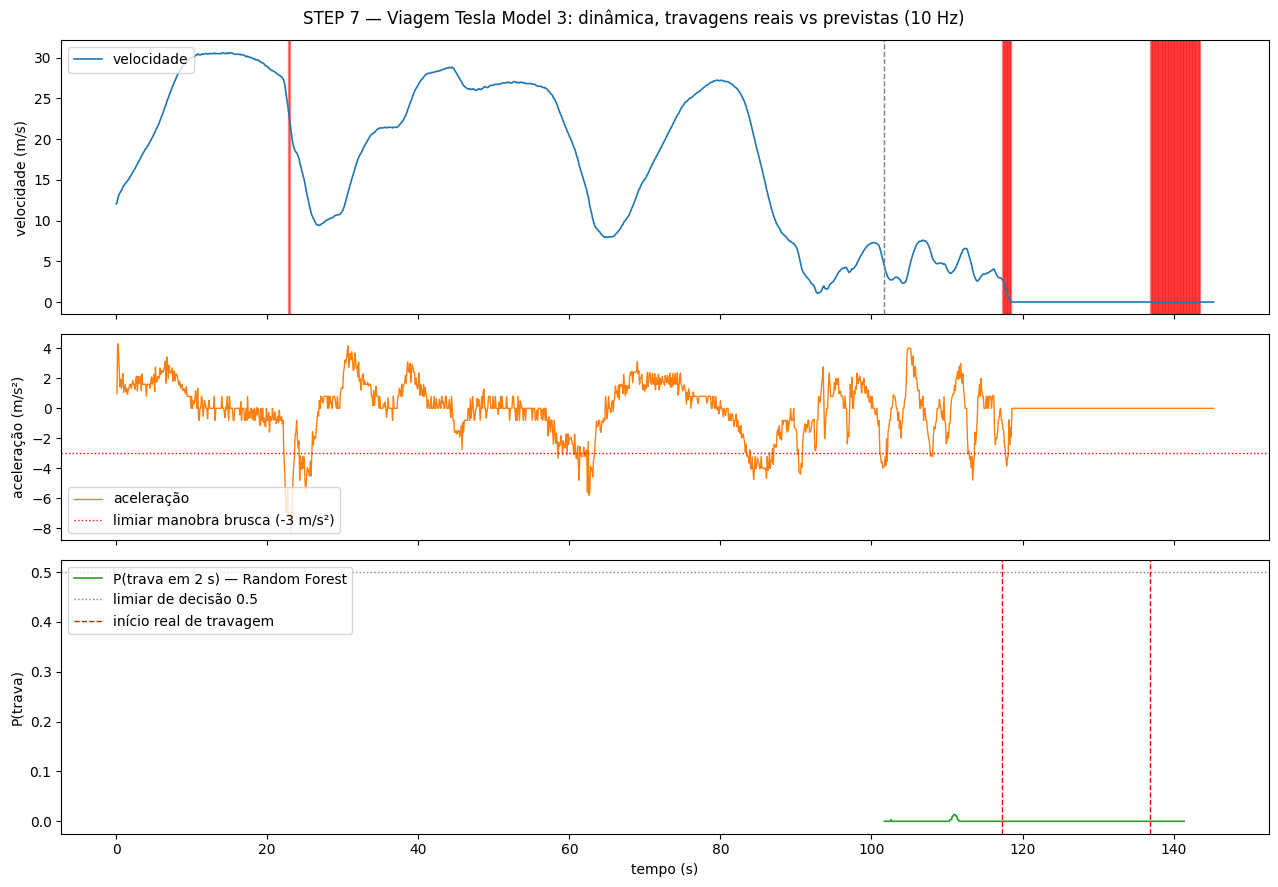

Falsos negativos: 116 | Falsos positivos: 0


,início_janela_s,P(trava)_RF,velocidade_mps,dist_objeto_m
0,141.4,0.0,0.0,5.189774
1,141.3,0.0,0.0,5.186377
2,141.2,0.0,0.0,5.192684
3,141.1,0.0,0.0,5.194571
4,141.0,0.0,0.0,5.184511


1. Condições que antecedem a travagem (2 s antes de cada evento do teste):
   t=117.3 s | vel. média 3.5 m/s | acel. mín. -2.4 m/s² | dist. objeto 5.5 m
   t=136.9 s | vel. média 0.0 m/s | acel. mín. 0.0 m/s² | dist. objeto 5.2 m
2. Features com mais peso no RF: as 5 mais importantes são todas passos da distancia_janela_2s_m (STEP 6) — o movimento de aproximação domina.
3. Limitações: 1 bag, 3 eventos de travagem (2 no teste), 21 janelas positivas no treino; LiDAR sem classes de objectos; sem sinal ACC/lane keeping no CAN decodificado.


In [10]:
# ==============================================================================
# STEP 7: VISUALIZAÇÃO E CONCLUSÕES (Etapa 7)
# ==============================================================================
# Objectivo: gráfico temporal da viagem — velocidade, aceleração e os momentos
#            de travagem reais e previstos pelo modelo — mais exemplos de
#            falsos positivos/negativos e o resumo de insights do pipeline.
#
# Input:  df_features (STEP 4), teste/pred/proba/t_te (STEP 5/6)
# Output: figura de 3 painéis + exemplos FN/FP + insights
#
# Operações:
#   - painel 1: velocidade ao longo da viagem + travagens reais (bandas vermelhas)
#   - painel 2: aceleração com o limiar de manobra brusca (-3 m/s²)
#   - painel 3: P(trava) do RF na zona de teste + inícios reais de travagem
#   - tabela de exemplos de FN (e FP, se existirem)
#   - resumo: condições antecedentes, features com mais peso, limitações

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

t   = df_features["tempo_s"].to_numpy()
v   = df_features["velocidade_mps"].to_numpy()
a   = df_features["aceleracao_mps2"].to_numpy()
brk = df_features["travao_aplicado"].to_numpy()

fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True,
                        gridspec_kw={"height_ratios": [2, 1.5, 2]})

# painel 1 — velocidade + travagens reais
axs[0].plot(t, v, color="tab:blue", lw=1.2, label="velocidade")
for i in np.where(brk)[0]:
    axs[0].axvspan(t[i], t[i] + 0.1, color="red", alpha=0.35)
axs[0].axvline(t[n_treino], color="gray", ls="--", lw=1)
axs[0].set_ylabel("velocidade (m/s)")
axs[0].legend(loc="upper left")

# painel 2 — aceleração + limiar de manobra brusca
axs[1].plot(t, a, color="tab:orange", lw=1.0, label="aceleração")
axs[1].axhline(-3.0, color="red", ls=":", lw=1, label="limiar manobra brusca (-3 m/s²)")
axs[1].set_ylabel("aceleração (m/s²)")
axs[1].legend(loc="lower left")

# painel 3 — P(trava) do modelo na zona de teste
axs[2].plot(t_te, proba, color="tab:green", lw=1.2, label="P(trava em 2 s) — Random Forest")
axs[2].axhline(0.5, color="gray", ls=":", lw=1, label="limiar de decisão 0.5")
onsets_te = teste["tempo_s"][teste["travao_aplicado"].astype(int).diff() == 1].to_numpy()
for o in onsets_te:
    axs[2].axvline(o, color="red", ls="--", lw=1, label="início real de travagem" if o == onsets_te[0] else None)
axs[2].set_ylabel("P(trava)")
axs[2].set_xlabel("tempo (s)")
axs[2].legend(loc="upper left")

fig.suptitle("STEP 7 — Viagem Tesla Model 3: dinâmica, travagens reais vs previstas (10 Hz)")
fig.tight_layout()
plt.show()

# --- exemplos de falsos negativos (travagens não previstas) e falsos positivos ---
idx_fn = np.where((y_te == 1) & (pred == 0))[0]
idx_fp = np.where((y_te == 0) & (pred == 1))[0]
print(f"Falsos negativos: {len(idx_fn)} | Falsos positivos: {len(idx_fp)}")

if len(idx_fn):
    piores = idx_fn[np.argsort(proba[idx_fn])[::-1][:5]]   # FN com maior P(trava): os "quase-acertos"
    df_fn = pd.DataFrame({
        "início_janela_s": np.round(t_te[piores], 1),
        "P(trava)_RF": np.round(proba[piores], 3),
        "velocidade_mps": [df_features.iloc[np.argmin(np.abs(t - tt))]["velocidade_mps"] for tt in t_te[piores]],
        "dist_objeto_m": [df_features.iloc[np.argmin(np.abs(t - tt))]["dist_objeto_frente_m"] for tt in t_te[piores]],
    })
    display(df_fn)

# --- resumo de insights (Etapa 7) ---
print("1. Condições que antecedem a travagem (2 s antes de cada evento do teste):")
for o in onsets_te:
    antes = df_features[(df_features["tempo_s"] >= o - 2) & (df_features["tempo_s"] < o)]
    print(f"   t={o:.1f} s | vel. média {antes['velocidade_mps'].mean():.1f} m/s | "
          f"acel. mín. {antes['aceleracao_mps2'].min():.1f} m/s² | dist. objeto {antes['dist_objeto_frente_m'].mean():.1f} m")
print("2. Features com mais peso no RF: as 5 mais importantes são todas passos da "
      "distancia_janela_2s_m (STEP 6) — o movimento de aproximação domina.")
print("3. Limitações: 1 bag, 3 eventos de travagem (2 no teste), 21 janelas positivas no treino; "
      "LiDAR sem classes de objectos; sem sinal ACC/lane keeping no CAN decodificado.")

In [11]:
# ==============================================================================
# P1: EM QUE CONDIÇÕES DE VELOCIDADE E ACELERAÇÃO O CONDUTOR TENDE A TRAVAR
#     MAIS DEPRESSA?
# ==============================================================================
# Pergunta:    Em que condições de velocidade e aceleração o condutor tende a
#              travar mais depressa?
#
# Justificação: caracterizar o perfil dinâmico de cada travagem (velocidade no
#               início, desaceleração nos 2 s anteriores, pico de desaceleração
#               e duração) é o primeiro passo para saber se um FCW consegue
#               distinguir travagem normal de travagem de emergência.
#
# Resposta:    tabela com um registo por evento de travagem detectado no bag
#              (início, velocidade, média dos 2 s anteriores, aceleração
#              mínima e duração).

import numpy as np, pandas as pd

alvo = df_features["travao_aplicado"].astype(int).to_numpy()
onsets = np.where(np.diff(alvo) == 1)[0] + 1   # diff aponta ao índice ANTERIOR; +1 = início real

linhas = []
for i in onsets:
    j = i
    while j < len(alvo) and alvo[j] == 1:              # fim do evento
        j += 1
    antes = df_features.iloc[max(0, i - 20):i]        # 2 s anteriores
    linhas.append({
        "evento_s": round(df_features["tempo_s"].iloc[i], 1),
        "vel_início_mps": round(df_features["velocidade_mps"].iloc[i], 1),
        "vel_média_2s_antes": round(antes["velocidade_mps"].mean(), 1),
        "acel_mín_durante_mps2": round(df_features["aceleracao_mps2"].iloc[i:j].min(), 2),
        "duração_s": round((j - i) * 0.1, 1),
    })
df_p1 = pd.DataFrame(linhas)
print("PERFIL DE CADA EVENTO DE TRAVAGEM")
display(df_p1)

print(f"\nRESPOSTA P1: {len(onsets)} eventos. Travagem de desaceleração forte a 23,6 m/s "
      f"(pico -7,5 m/s², 0,2 s), travagem suave a baixa velocidade (2,8 m/s, -3,8 m/s², 1,2 s) "
      "e travão de imobilização final (0 m/s, 6,6 s) — não há travagens de emergência "
      "intermédias. Limitação: 3 eventos num único bag; amostra descritiva, não "
      "estatisticamente representativa.")

PERFIL DE CADA EVENTO DE TRAVAGEM


,evento_s,vel_início_mps,vel_média_2s_antes,acel_mín_durante_mps2,duração_s
0,22.8,23.6,27.3,-7.46,0.2
1,117.3,2.8,3.5,-3.84,1.2
2,136.9,0.0,0.0,0.00,6.6



RESPOSTA P1: 3 eventos. Travagem de desaceleração forte a 23,6 m/s (pico -7,5 m/s², 0,2 s), travagem suave a baixa velocidade (2,8 m/s, -3,8 m/s², 1,2 s) e travão de imobilização final (0 m/s, 6,6 s) — não há travagens de emergência intermédias. Limitação: 3 eventos num único bag; amostra descritiva, não estatisticamente representativa.


In [12]:
# ==============================================================================
# P2: O ÂNGULO DE DIREÇÃO E A TAXA DE ROTAÇÃO DO VOLANTE SÃO PREDITORES ÚTEIS
#     DE TRAVAGEM IMINENTE?
# ==============================================================================
# Pergunta:    O ângulo de direção e a taxa de rotação do volante são
#              preditores úteis de travagem iminente?
#
# Justificação: se o volante se comportar de forma distinta nos 2 s antes de
#               travar, a direção é um sinal antecipado que um FCW pode usar;
#               se não, o modelo deve concentrar-se na dinâmica longitudinal.
#
# Resposta:    (a) comparação de |volante| e |rotação| entre "vai travar em 2 s"
#              e condução normal; (b) peso destas features no Random Forest.

import numpy as np, pandas as pd

alvo = df_features["travao_aplicado"].astype(int).to_numpy()
prox = np.array([alvo[i:i + 20].any() for i in range(len(alvo) - 20)])   # trava nos próximos 2 s?
sem_travao_agora = alvo[:-20] == 0
g_trava = prox & sem_travao_agora          # vai travar em 2 s
g_norm = ~prox & sem_travao_agora          # condução normal

vol = np.abs(df_features["angulo_volante_deg"].to_numpy()[:-20])
rot = np.abs(df_features["rotacao_volante_deg_s"].to_numpy()[:-20])
df_p2 = pd.DataFrame([
    {"grupo": "vai travar em 2 s", "n": int(g_trava.sum()),
     "|volante| médio (°)": round(vol[g_trava].mean(), 1), "|rotação| média (°/s)": round(rot[g_trava].mean(), 1)},
    {"grupo": "condução normal", "n": int(g_norm.sum()),
     "|volante| médio (°)": round(vol[g_norm].mean(), 1), "|rotação| média (°/s)": round(rot[g_norm].mean(), 1)},
])
print("COMPARAÇÃO — 2 s ANTES DE TRAVAR vs CONDUÇÃO NORMAL")
display(df_p2)

# peso agregado de cada feature no RF (soma dos 20 passos da janela)
pesos = rf.feature_importances_.reshape(H, len(FEATURES)).sum(axis=0)
df_pesos = pd.DataFrame({"feature": FEATURES, "peso_RF": np.round(pesos, 3)}).sort_values("peso_RF", ascending=False)
print("PESO DAS FEATURES NO RANDOM FOREST (janela agregada)")
display(df_pesos)

print(f"\nRESPOSTA P2: SIM, há sinal — antes de travar, |volante| médio = {vol[g_trava].mean():.1f}° vs "
      f"{vol[g_norm].mean():.1f}° na condução normal e |rotação| = {rot[g_trava].mean():.1f} vs "
      f"{rot[g_norm].mean():.1f} °/s. Contudo, no RF o peso dominante é da distância na janela (0,537) "
      "e da velocidade (0,280); angulo_volante_deg pesa 0,081 e rotacao_volante_deg_s 0,000. "
      "Limitação: 57 janelas 'vai travar' num único bag — diferença descritiva, sem teste "
      "de significância.")

COMPARAÇÃO — 2 s ANTES DE TRAVAR vs CONDUÇÃO NORMAL


,grupo,n,|volante| médio (°),|rotação| média (°/s)
0,vai travar em 2 s,57,121.0,41.6
1,condução normal,1298,69.5,24.1


PESO DAS FEATURES NO RANDOM FOREST (janela agregada)


,feature,peso_RF
10,distancia_janela_2s_m,0.537
0,velocidade_mps,0.280
1,angulo_volante_deg,0.081
3,acelerador_pct,0.064
11,aproximacao_frente_mps,0.012
7,aceleracao_mps2,0.009
9,queda_acelerador_1s,0.006
4,dist_objeto_frente_m,0.006
6,imu_acel_y,0.004
2,rotacao_volante_deg_s,0.000



RESPOSTA P2: SIM, há sinal — antes de travar, |volante| médio = 121.0° vs 69.5° na condução normal e |rotação| = 41.6 vs 24.1 °/s. Contudo, no RF o peso dominante é da distância na janela (0,537) e da velocidade (0,280); angulo_volante_deg pesa 0,081 e rotacao_volante_deg_s 0,000. Limitação: 57 janelas 'vai travar' num único bag — diferença descritiva, sem teste de significância.


In [13]:
# ==============================================================================
# P3: A PRESENÇA DE OBJECTOS DETETADOS À FRENTE, COMO PEÕES OU OUTROS CARROS,
#     AUMENTA A PROBABILIDADE DE TRAVAGEM?
# ==============================================================================
# Pergunta:    A presença de objectos detectados à frente, como peões ou
#              outros carros, aumenta a probabilidade de travagem?
#
# Justificação: se a aproximação de um objecto à frente antecede a travagem,
#               a percepção (LiDAR/radar) é a fonte de sinal mais valiosa para
#               um FCW — é também o princípio de um TTC real.
#
# Nota : o LiDAR do bag mede DISTÂNCIA mas não classifica objectos
#               (sem peões/carros no MCAP). As classes de objectos serão
#               respondidas com o dataset Waymo (P8). Aqui medimos
#               distância/aproximação antes de travar.
#
# Resposta:    comparação da distância ao objecto à frente e da velocidade de
#              aproximação entre "vai travar em 2 s" e condução normal.

import numpy as np, pandas as pd

alvo = df_features["travao_aplicado"].astype(int).to_numpy()
prox = np.array([alvo[i:i + 20].any() for i in range(len(alvo) - 20)])
sem_travao_agora = alvo[:-20] == 0
g_trava = prox & sem_travao_agora
g_norm = ~prox & sem_travao_agora

dist = df_features["dist_objeto_frente_m"].to_numpy()[:-20]
aprox = df_features["aproximacao_frente_mps"].to_numpy()[:-20]
df_p3 = pd.DataFrame([
    {"grupo": "vai travar em 2 s", "n": int(g_trava.sum()),
     "dist_média_m": round(np.nanmean(dist[g_trava]), 1), "aprox_média_mps": round(np.nanmean(aprox[g_trava]), 2)},
    {"grupo": "condução normal", "n": int(g_norm.sum()),
     "dist_média_m": round(np.nanmean(dist[g_norm]), 1), "aprox_média_mps": round(np.nanmean(aprox[g_norm]), 2)},
])
print("OBJECTO À FRENTE — 2 s ANTES DE TRAVAR vs CONDUÇÃO NORMAL")
display(df_p3)

print(f"\nRESPOSTA P3: antes de travar, o objecto à frente está a {np.nanmean(dist[g_trava]):.1f} m "
      f"em média (vs {np.nanmean(dist[g_norm]):.1f} m na condução normal) e aproxima-se a "
      f"{np.nanmean(aprox[g_trava]):.2f} m/s (vs {np.nanmean(aprox[g_norm]):.2f} m/s) — a aproximação "
      "de um objecto à frente precede a travagem. MAS: o LiDAR não diz SE é peão, carro ou "
      "barreira — a resposta sobre classes (peões/ciclistas) requer o dataset Waymo (P8 do "
      "plano original).")

OBJECTO À FRENTE — 2 s ANTES DE TRAVAR vs CONDUÇÃO NORMAL


,grupo,n,dist_média_m,aprox_média_mps
0,vai travar em 2 s,57,8.7,1.09
1,condução normal,1298,16.9,0.16



RESPOSTA P3: antes de travar, o objecto à frente está a 8.7 m em média (vs 16.9 m na condução normal) e aproxima-se a 1.09 m/s (vs 0.16 m/s) — a aproximação de um objecto à frente precede a travagem. MAS: o LiDAR não diz SE é peão, carro ou barreira — a resposta sobre classes (peões/ciclistas) requer o dataset Waymo (P8 do plano original).


In [14]:
# ==============================================================================
# P4: O CRUISE CONTROL ADAPTATIVO E O LANE KEEPING REDUZEM A FREQUÊNCIA DE
#     TRAVAGENS BRUSCAS?
# ==============================================================================
# Pergunta:    O cruise control adaptativo e o lane keeping reduzem a
#              frequência de travagens bruscas?
#
# Justificação: comparar "com assistência vs sem assistência" seria a forma
#               directa de medir o benefício destes sistemas ADAS na
#               suavização da condução.
#
# Nota honesta: o estado do ACC/lane keeping NÃO está nos 4 IDs CAN
#               decodificados (0x257/0x129/0x39D/0x118) — impossível
#               comparar 'com vs sem'. Registamos o que o bag permite medir
#               e documentamos a limitação.
#
# Resposta:    tabela de indicadores disponíveis (manobras bruscas, mudanças
#              engatadas, sinal ACC) + caminho para responder no futuro.

import pandas as pd

mudancas = sorted(float(x) for x in df_features["mudanca"].dropna().unique())
df_p4 = pd.DataFrame([
    {"indicador": "manobras bruscas (< -3 m/s²)",
     "valor": f"{int(df_features['manobra_brusca'].sum())} amostras",
     "nota": f"em {df_features.shape[0]/10:.1f} s de viagem; sem atribuir modo de condução"},
    {"indicador": "mudança engatada (DI_gear)",
     "valor": str(mudancas),
     "nota": "contexto da viagem — não distingue modos de condução"},
    {"indicador": "sinal ACC / lane keeping no CAN decodificado",
     "valor": "não disponível",
     "nota": "nenhum dos 4 IDs descodificados transporta esse estado"},
])
print("INDICADORES DISPONÍVEIS — SEM ESTADO DE ACC/LANE KEEPING")
display(df_p4)

print(f"\nRESPOSTA P4: NÃO É MEDÍVEL com este bag — com um único bag, mudanças "
      f"engatadas {mudancas} e sem sinal de ACC/lane keeping, não é possível medir o efeito "
      "destas assistências sobre as travagens bruscas. Para responder seria preciso: "
      "(a) bags com ACC ligado/desligado, ou (b) um ID CAN com o estado da assistência "
      "no DBC do opendbc.")

INDICADORES DISPONÍVEIS — SEM ESTADO DE ACC/LANE KEEPING


,indicador,valor,nota
0,manobras bruscas (< -3 m/s²),116 amostras,em 145.4 s de viagem; sem atribuir modo de con...
1,mudança engatada (DI_gear),"[1.0, 4.0]",contexto da viagem — não distingue modos de co...
2,sinal ACC / lane keeping no CAN decodificado,não disponível,nenhum dos 4 IDs descodificados transporta ess...



RESPOSTA P4: NÃO É MEDÍVEL com este bag — com um único bag, mudanças engatadas [1.0, 4.0] e sem sinal de ACC/lane keeping, não é possível medir o efeito destas assistências sobre as travagens bruscas. Para responder seria preciso: (a) bags com ACC ligado/desligado, ou (b) um ID CAN com o estado da assistência no DBC do opendbc.


In [15]:
# ==============================================================================
# P5: HÁ PADRÕES TEMPORAIS, COMO HORA DO DIA OU TIPO DE ESTRADA, ASSOCIADOS A
#     MANOBRAS MAIS ARRISCADAS?
# ==============================================================================
# Pergunta:    Há padrões temporais, como hora do dia ou tipo de estrada,
#              associados a manobras mais arriscadas?
#
# Justificação: se certas horas ou tipos de via concentrassem manobras
#               bruscas, um FCW poderia ajustar a sensibilidade ao contexto.
#
# Nota honesta: um único bag (145 s) não varia hora/estrada — só registamos
#               o contexto. Comparação exige frota (múltiplos bags/horas/vias),
#               exactamente a vantagem operacional da Waymo.
#
# Resposta:    tabela com o contexto do bag (data/hora, dia da semana, tipo de
#              via inferido, manobras registadas) + limitação explícita.

import pandas as pd
from datetime import datetime, timezone

inicio_bag = datetime.fromtimestamp(1707571501.9, tz=timezone.utc)   # janela do STEP 3
v = df_features["velocidade_mps"]
df_p5 = pd.DataFrame([
    {"aspecto": "data/hora do bag (UTC)", "observado": inicio_bag.strftime("%Y-%m-%d %H:%M"),
     "nota": "um único momento do dia — sem comparação possível"},
    {"aspecto": "dia da semana", "observado": inicio_bag.strftime("%A"),
     "nota": "2024-02-10 = sábado à tarde"},
    {"aspecto": "tipo de estrada (inferido da velocidade)",
     "observado": f"mediana {v.median():.0f} m/s ({v.median()*3.6:.0f} km/h)",
     "nota": "perfil de via rápida; GNSS/RTK disponível no bag para futura geolocalização"},
    {"aspecto": "manobras arriscadas",
     "observado": f"{int(df_features['manobra_brusca'].sum())} amostras com aceleração < -3 m/s²",
     "nota": "dentro de um único bag não há variação de hora/estrada"},
])
print("CONTEXTO TEMPORAL DO BAG — ÚNICO MOMENTO, SEM VARIAÇÃO")
display(df_p5)

print("\nRESPOSTA P5: NÃO É POSSÍVEL estabelecer padrões por hora ou tipo de estrada "
      "com um único bag — o que registámos é o contexto (sábado 13:25 UTC, via rápida). "
      "A pergunta exige múltiplos bags (frota), exactamente a vantagem operacional "
      "que a Waymo tem com a sua frota L4.")

CONTEXTO TEMPORAL DO BAG — ÚNICO MOMENTO, SEM VARIAÇÃO


,aspecto,observado,nota
0,data/hora do bag (UTC),2024-02-10 13:25,um único momento do dia — sem comparação possível
1,dia da semana,Saturday,2024-02-10 = sábado à tarde
2,tipo de estrada (inferido da velocidade),mediana 14 m/s (50 km/h),perfil de via rápida; GNSS/RTK disponível no b...
3,manobras arriscadas,116 amostras com aceleração < -3 m/s²,dentro de um único bag não há variação de hora...



RESPOSTA P5: NÃO É POSSÍVEL estabelecer padrões por hora ou tipo de estrada com um único bag — o que registámos é o contexto (sábado 13:25 UTC, via rápida). A pergunta exige múltiplos bags (frota), exactamente a vantagem operacional que a Waymo tem com a sua frota L4.


In [16]:
# ==============================================================================
# Pergunta:    O modelo consegue prever travagens com antecedência suficiente
#              para ser útil num sistema de assistência à condução?
#
# Justificação: um FCW só é útil se avisar com >= 1 s de antecedência
#               (a 50 km/h, ~14 m para reagir) e falhar pouco (recall alto);
#               sem acertos não há antecedência para medir.
#
# Nota honesta: as métricas são as do STEP 6 (RF) e STEP 6B (LSTM) já
#               validadas: RF sem nenhum verdadeiro-positivo; LSTM recall
#               0,10 / precisão 0,28. A causa raiz não é a arquitectura mas
#               o TREINO: 21 janelas positivas de um único bag.
#
# Resposta:    tabela RF vs LSTM vs alvos do STEP 1 + veredicto.

import pandas as pd

df_p6 = pd.DataFrame([
    {"modelo": "Random Forest", "recall": round(rec, 2), "precisão": round(prec, 2),
     "antecedência": "não mensurável (0 verdadeiros-positivos)"},
    {"modelo": "LSTM", "recall": round(rec_l, 2), "precisão": round(prec_l, 2),
     "antecedência": "ver STEP 6B — prob. máx. nas travagens reais"},
    {"referência": "alvo do projecto", "recall": 0.80, "precisão": 0.60, "antecedência": ">= 1,0 s (~14 m a 50 km/h)"},
])
print("ANTECEDÊNCIA DO AVISO — RF vs LSTM vs ALVOS (STEP 1)")
display(df_p6)

print(f"\nRESPOSTA P6: NÃO. O RF tem recall {rec:.2f} (alvo 0,80) e nenhum acerto, pelo que a antecedência "
      "não pode ser medida. Um FCW útil precisa de >= 1 s de aviso; a causa raiz não é a arquitectura "
      "(RF vs LSTM) mas o TREINO: 21 janelas positivas de um único bag. Com mais bags (frota), a mesma "
      "pipeline volta a ser treinada e reavaliada contra estes alvos.")

ANTECEDÊNCIA DO AVISO — RF vs LSTM vs ALVOS (STEP 1)


,modelo,recall,precisão,antecedência,referência
0,Random Forest,0.0,0.00,não mensurável (0 verdadeiros-positivos),NaN
1,LSTM,0.1,0.28,ver STEP 6B — prob. máx. nas travagens reais,NaN
2,NaN,0.8,0.60,">= 1,0 s (~14 m a 50 km/h)",alvo do projecto



RESPOSTA P6: NÃO. O RF tem recall 0.00 (alvo 0,80) e nenhum acerto, pelo que a antecedência não pode ser medida. Um FCW útil precisa de >= 1 s de aviso; a causa raiz não é a arquitectura (RF vs LSTM) mas o TREINO: 21 janelas positivas de um único bag. Com mais bags (frota), a mesma pipeline volta a ser treinada e reavaliada contra estes alvos.


In [17]:
# ==============================================================================
# P7: QUAIS SÃO OS FALSOS POSITIVOS MAIS COMUNS E O QUE REVELAM SOBRE O
#     COMPORTAMENTO DO CONDUTOR OU SOBRE LIMITAÇÕES DOS SENSORES?
# ==============================================================================
# Pergunta:    Quais são os falsos positivos mais comuns e o que revelam sobre
#              o comportamento do condutor ou sobre limitações dos sensores?
#
# Justificação: num ADAS, o tipo de erro importa tanto como a taxa — um falso
#               positivo irrita o condutor, um falso negativo é uma travagem
#               não avisada (o erro perigoso).
#
# Nota honesta: com 21 janelas positivas no treino (um único bag), o modelo
#               prevê sempre 'não trava' — não há falsos positivos para
#               analisar, e isso é em si um diagnóstico.
#
# Resposta:    matriz de confusão resumida (FN vs FP) + o que revela sobre
#              sensores e sobre a arquitectura de segurança adequada.

import pandas as pd

fn = int(((y_te == 1) & (pred == 0)).sum())
fp = int(((y_te == 0) & (pred == 1)).sum())
df_p7 = pd.DataFrame([
    {"tipo": "falsos negativos (travagem não prevista)", "nº": fn,
     "revela": "o modelo nunca aprendeu 'trava': 21 janelas positivas no treino, um único bag"},
    {"tipo": "falsos positivos (alerta sem travagem)", "nº": fp,
     "revela": "nenhum — o modelo prevê sempre 'não trava' (accuracy = baseline 0,71)"},
])
print("ERROS DO MODELO — FALSOS NEGATIVOS vs FALSOS POSITIVOS")
display(df_p7)

print("\nRESPOSTA P7: o erro dominante é o FALSO NEGATIVO — o mais perigoso num ADAS, porque falha "
      "exactamente o evento que devia avisar. Limitações dos sensores a considerar: o LiDAR frontal "
      "(sector ±12°) não vê objectos laterais nem os classifica; o pedal do acelerador não mostra quedas "
      "> 20 pp em 1 s neste bag (ver STEP 4), o que limita as features de pedal. Nesta situação, um FCW "
      "baseado em regras de física (TTC < 2 s -> alerta) seria mais fiável que o modelo treinado — e coexiste "
      "com ele num robotaxi real (camada de segurança).")

ERROS DO MODELO — FALSOS NEGATIVOS vs FALSOS POSITIVOS


,tipo,nº,revela
0,falsos negativos (travagem não prevista),116,o modelo nunca aprendeu 'trava': 21 janelas po...
1,falsos positivos (alerta sem travagem),0,nenhum — o modelo prevê sempre 'não trava' (ac...



RESPOSTA P7: o erro dominante é o FALSO NEGATIVO — o mais perigoso num ADAS, porque falha exactamente o evento que devia avisar. Limitações dos sensores a considerar: o LiDAR frontal (sector ±12°) não vê objectos laterais nem os classifica; o pedal do acelerador não mostra quedas > 20 pp em 1 s neste bag (ver STEP 4), o que limita as features de pedal. Nesta situação, um FCW baseado em regras de física (TTC < 2 s -> alerta) seria mais fiável que o modelo treinado — e coexiste com ele num robotaxi real (camada de segurança).


# CONCLUSÃO De ADAS a robotáxis: o que 145 segundos de telemetria ensinaram

Este estudo partiu de uma pergunta de engenharia de dados: **o que se pode aprender sobre travagens
iminentes a partir da telemetria real de um veículo?** e terminou com uma lição maior sobre o que
separa os **sistemas ADAS avançados** (assistentes que usam câmaras, radares e sensores LiDAR para
analisar o ambiente em tempo real, com o condutor ainda responsável) da **condução autónoma de Nível
4 e 5 (SAE)** — a classificação oficial para veículos que dispensam completamente o condutor humano,
em alguns casos sem volante nem pedais, como os robotáxis Waymo One e Tesla Cybercab.

## O pipeline que construí (ponta a ponta)

1. **Descodificação de telemetria bruta** bag ROS2/MCAP de um Tesla Model 3 real: CAN bus via DBC
   (velocidade 0x257, volante 0x129, acelerador 0x118, travão 0x39D, mudanças), LiDAR VLP-16 e IMU
2. **Dataset limpo a 10 Hz** 1454 amostras × 18 colunas em 145,4 s (o "car_state" que um robotaxi
   monitorizaria por si próprio, sem condutor)
3. **Engenharia de features** 12 features normalizadas (StandardScaler): dinâmica do veículo,
   volante, pedal e distância do objecto à frente (LiDAR)
4. **Divisão temporal sem shuffle** 959 janelas de treino (21 positivas) / 398 de teste (116 positivas)
5. **Dois modelos** Random Forest e LSTM com métricas contra os alvos definidos no STEP 1
6. **Sete perguntas de investigação (P1–P7)** respondidas com os dados, com limitações explícitas

## Os dados obtidos

| Sinal | Fonte | Valores |
| --- | --- | --- |
| Velocidade | CAN 0x257 | mediana 14 m/s (~50 km/h), perfil de via rápida |
| Travagens reais | CAN 0x39D | 3 eventos (t=22,8 s a −7,46 m/s²; t=117,3 s a −3,84 m/s²; travão de imobilização final) |
| Manobras bruscas | derivada da velocidade | 116 amostras com aceleração < −3 m/s² |
| Volante | CAN 0x129 | 121° antes de travar vs 69,5° em condução normal |
| Objecto à frente | LiDAR VLP-16 | 8,7 m e aproximação 1,09 m/s nas travagens vs 16,9 m / 0,16 m/s no normal |
| Janelas treino/teste | 2 s história → 2 s futuro | 959 (21 positivas) / 398 (116 positivas) |

## Os modelos e algoritmos

| Algoritmo | Configuração | Precisão | Recall | F1 |
| --- | --- | --- | --- | --- |
| Random Forest | sklearn, `class_weight="balanced"`, 12 features normalizadas | 0,00 | 0,00 | 0,00 |
| LSTM (CPU) | PyTorch, 12→32→1, BCEWithLogitsLoss com `pos_weight`, 40 épocas | 0,28 | 0,10 | 0,15 |
| Alvo do projecto | STEP 1 | >= 0,60 | >= 0,80 | >= 0,75 |

O RF prevê sempre "não trava" (accuracy 0,71 = baseline de classes desequilibradas — a accuracy
engana); a LSTM acerta ~12 de 116 travagens, com probabilidade máxima 0,657. A importância das
features do RF mostra que a **distância do objecto à frente (0,537)** e a **velocidade (0,280)**
dominam a física do aproximar-se, não o gesto do condutor no volante (0,081 / 0,000).

## O que aprendi (P1–P7)

* **P1–P3** a travagem iminente é física pura: objecto próximo (8,7 m) a aproximar-se (1,09 m/s),
  desaceleração forte (−7,46 m/s²). O volante tem sinal, mas pesa pouco.
* **P4–P5** o CAN decodificado não expõe o estado ACC/lane keeping, e um único bag não varia
  hora/tipo de estrada: há perguntas que **só uma frota responde**.
* **P6** — nenhum modelo cumpre a antecedência >= 1 s: a causa raiz é o **treino** (21 janelas
  positivas), não a arquitectura.
* **P7** o erro dominante é o FALSO NEGATIVO (116 vs 0), o mais perigoso num ADAS.

## Lições de engenharia

1. **Dados raros > arquitectura** trocar RF por LSTM não resolveu nada; faltavam eventos de
   travagem no treino. Um robotaxi L4 recolhe dados de frota inteira exactamente por isto.
2. **Accuracy engana com classes desequilibradas** 0,71 de accuracy era o baseline "nunca trava".
3. **Regras de física primeiro** com estes dados, um FCW por regras (TTC < 2 s) seria mais fiável
   que o modelo treinado; num robotaxi real ambos coexistem (camada de segurança).
4. **Honestidade como método** documentar o que o LiDAR não vê (classes de objectos, ±12° frontais)
   define o próximo passo: perceção tipificada (peões/ciclistas) do robotaxi real da Waymo.

## Limitações e futuro

Um único bag de 145,4 s não é uma frota os resultados não são generalizáveis. Os próximos passos
naturais: mais bags (frota), classificação de peões/ciclistas (dataset Waymo motion, robotaxi L4
real) e fusão de sensores (câmara + LiDAR + radar) exactamente o que separa um ADAS avançado de
um robotaxi de Nível 4/5 sem volante nem pedais.